<a href="https://colab.research.google.com/github/zcleips/Comparative-Study-of-Generative-Models-on-Fashion-MNIST/blob/main/DeepLearningAssignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

import os
import json
import random
import platform
import time
from pathlib import Path

import numpy as np
import torch
import torchvision

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Generative_Models_Take_Home"
)

DIRS = {
    "data": PROJECT_DIR / "data",
    "checkpoints": PROJECT_DIR / "checkpoints",
    "logs": PROJECT_DIR / "logs",
    "metrics": PROJECT_DIR / "metrics",
    "figures": PROJECT_DIR / "figures",
    "src": PROJECT_DIR / "src",
    "reports": PROJECT_DIR / "reports",
}

PROJECT_DIR.mkdir(parents=True, exist_ok=True)

for directory in DIRS.values():
    directory.mkdir(parents=True, exist_ok=True)

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

CONFIG = {
    "project_name": "Generative Models Comparative Study",
    "dataset": "FashionMNIST",
    "seed": SEED,
    "train_ratio": 0.80,
    "validation_ratio": 0.10,
    "test_ratio": 0.10,
    "batch_size": 128,
    "image_channels": 1,
    "image_height": 28,
    "image_width": 28,
    "num_classes": 10,
    "device": str(DEVICE),
}

config_path = PROJECT_DIR / "config.json"

with open(config_path, "w") as file:
    json.dump(CONFIG, file, indent=4)

environment = {
    "python_version": platform.python_version(),
    "pytorch_version": torch.__version__,
    "torchvision_version": torchvision.__version__,
    "numpy_version": np.__version__,
    "device": str(DEVICE),
    "cuda_available": torch.cuda.is_available(),
    "cuda_version": torch.version.cuda,
    "seed": SEED,
}

env_path = DIRS["logs"] / "environment.json"

with open(env_path, "w") as file:
    json.dump(environment, file, indent=4)

print("=" * 55)
print("PROJECT SETUP COMPLETE")
print("=" * 55)

print("\nProject directory:")
print(PROJECT_DIR)

print("\nSubdirectories:")
for name, directory in DIRS.items():
    print(f"{name:12s}: {directory.exists()} | {directory}")

print("\nEnvironment:")
for key, value in environment.items():
    print(f"{key:22s}: {value}")

print("\nConfiguration saved to:", config_path)
print("Environment saved to:", env_path)

Mounted at /content/drive
PROJECT SETUP COMPLETE

Project directory:
/content/drive/MyDrive/Generative_Models_Take_Home

Subdirectories:
data        : True | /content/drive/MyDrive/Generative_Models_Take_Home/data
checkpoints : True | /content/drive/MyDrive/Generative_Models_Take_Home/checkpoints
logs        : True | /content/drive/MyDrive/Generative_Models_Take_Home/logs
metrics     : True | /content/drive/MyDrive/Generative_Models_Take_Home/metrics
figures     : True | /content/drive/MyDrive/Generative_Models_Take_Home/figures
src         : True | /content/drive/MyDrive/Generative_Models_Take_Home/src
reports     : True | /content/drive/MyDrive/Generative_Models_Take_Home/reports

Environment:
python_version        : 3.13.16
pytorch_version       : 2.11.0+cu130
torchvision_version   : 0.26.0+cu130
numpy_version         : 2.1.3
device                : cuda
cuda_available        : True
cuda_version          : 13.0
seed                  : 42

Configuration saved to: /content/drive/MyDri

FASHION-MNIST PIPELINE VERIFIED
Total images       : 70000
Training images    : 56000
Validation images  : 7000
Test images        : 7000
Batch image shape  : (128, 1, 28, 28)
Pixel range        : 0.000 to 1.000
Batch size         : 128
Device             : cuda
Split indices saved: /content/drive/MyDrive/Generative_Models_Take_Home/data/fashion_mnist_split_indices.npz

Class distribution per split:

Train:
  T-shirt/top : 5600
  Trouser     : 5600
  Pullover    : 5600
  Dress       : 5600
  Coat        : 5600
  Sandal      : 5600
  Shirt       : 5600
  Sneaker     : 5600
  Bag         : 5600
  Ankle boot  : 5600

Validation:
  T-shirt/top : 700
  Trouser     : 700
  Pullover    : 700
  Dress       : 700
  Coat        : 700
  Sandal      : 700
  Shirt       : 700
  Sneaker     : 700
  Bag         : 700
  Ankle boot  : 700

Test:
  T-shirt/top : 700
  Trouser     : 700
  Pullover    : 700
  Dress       : 700
  Coat        : 700
  Sandal      : 700
  Shirt       : 700
  Sneaker     : 700

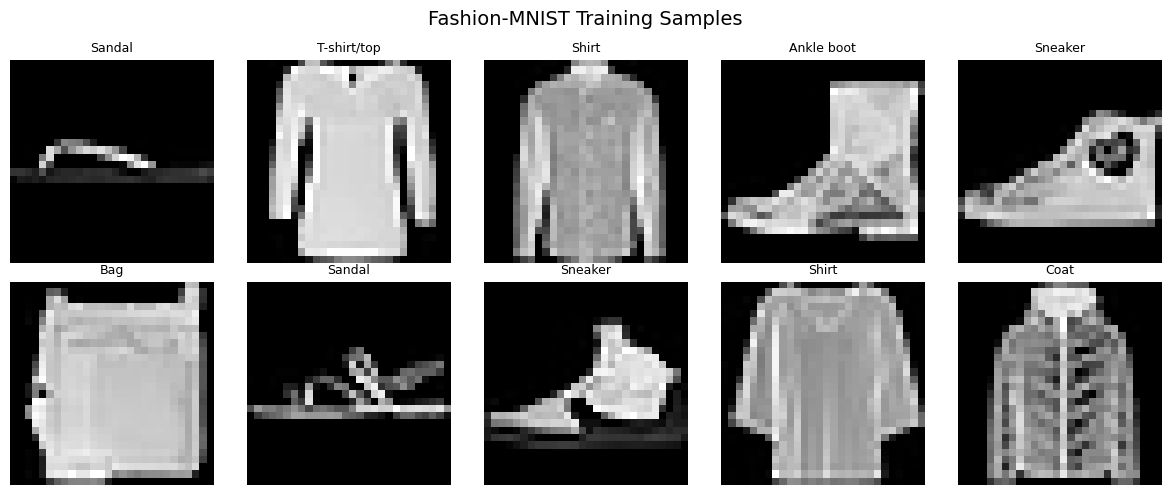


Sample figure saved: /content/drive/MyDrive/Generative_Models_Take_Home/figures/dataset_samples.png

STEP 2A COMPLETE


In [ ]:
import json
import numpy as np
import torch
import matplotlib.pyplot as plt

from pathlib import Path
from torch.utils.data import (
    ConcatDataset, Subset, DataLoader
)
from torchvision import datasets, transforms
from sklearn.model_selection import train_test_split

SEED = 42
BATCH_SIZE = 128
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Generative_Models_Take_Home"
)
DATA_DIR = PROJECT_DIR / "data"
FIGURES_DIR = PROJECT_DIR / "figures"
LOGS_DIR = PROJECT_DIR / "logs"

transform = transforms.ToTensor()

train_original = datasets.FashionMNIST(
    root=str(DATA_DIR),
    train=True,
    download=True,
    transform=transform
)

test_original = datasets.FashionMNIST(
    root=str(DATA_DIR),
    train=False,
    download=True,
    transform=transform
)

full_dataset = ConcatDataset([
    train_original,
    test_original
])

labels = np.concatenate([
    train_original.targets.numpy(),
    test_original.targets.numpy()
])

assert len(full_dataset) == 70000
assert len(labels) == 70000

all_indices = np.arange(len(full_dataset))

train_indices, remaining_indices = train_test_split(
    all_indices,
    test_size=0.20,
    random_state=SEED,
    stratify=labels
)

val_indices, test_indices = train_test_split(
    remaining_indices,
    test_size=0.50,
    random_state=SEED,
    stratify=labels[remaining_indices]
)

assert len(train_indices) == 56000
assert len(val_indices) == 7000
assert len(test_indices) == 7000

assert len(set(train_indices) & set(val_indices)) == 0
assert len(set(train_indices) & set(test_indices)) == 0
assert len(set(val_indices) & set(test_indices)) == 0

assert len(np.concatenate([
    train_indices, val_indices, test_indices
])) == 70000

train_dataset = Subset(full_dataset, train_indices.tolist())
val_dataset = Subset(full_dataset, val_indices.tolist())
test_dataset = Subset(full_dataset, test_indices.tolist())

split_path = DATA_DIR / "fashion_mnist_split_indices.npz"

np.savez(
    split_path,
    train_indices=train_indices,
    val_indices=val_indices,
    test_indices=test_indices
)

split_info = {
    "dataset": "Fashion-MNIST",
    "total_images": 70000,
    "train_size": len(train_indices),
    "validation_size": len(val_indices),
    "test_size": len(test_indices),
    "seed": SEED,
    "stratified": True,
    "split_ratios": {
        "train": 0.80,
        "validation": 0.10,
        "test": 0.10
    },
    "pixel_range": [0.0, 1.0],
    "image_shape": [1, 28, 28]
}

with open(DATA_DIR / "split_info.json", "w") as f:
    json.dump(split_info, f, indent=4)

loader_generator = torch.Generator()
loader_generator.manual_seed(SEED)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    generator=loader_generator,
    num_workers=2,
    pin_memory=(DEVICE.type == "cuda")
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=(DEVICE.type == "cuda")
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=(DEVICE.type == "cuda")
)

CLASS_NAMES = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

images, batch_labels = next(iter(train_loader))

print("=" * 55)
print("FASHION-MNIST PIPELINE VERIFIED")
print("=" * 55)
print(f"Total images       : {len(full_dataset)}")
print(f"Training images    : {len(train_dataset)}")
print(f"Validation images  : {len(val_dataset)}")
print(f"Test images        : {len(test_dataset)}")
print(f"Batch image shape  : {tuple(images.shape)}")
print(f"Pixel range        : {images.min().item():.3f} to {images.max().item():.3f}")
print(f"Batch size         : {BATCH_SIZE}")
print(f"Device             : {DEVICE}")
print(f"Split indices saved: {split_path}")

print("\nClass distribution per split:")
for split_name, indices in [
    ("Train", train_indices),
    ("Validation", val_indices),
    ("Test", test_indices)
]:
    counts = np.bincount(labels[indices], minlength=10)
    print(f"\n{split_name}:")
    for i, count in enumerate(counts):
        print(f"  {CLASS_NAMES[i]:12s}: {count}")

fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, ax in enumerate(axes.flat):
    image, label = train_dataset[i]
    ax.imshow(image.squeeze(0), cmap="gray", vmin=0, vmax=1)
    ax.set_title(CLASS_NAMES[label], fontsize=9)
    ax.axis("off")

fig.suptitle("Fashion-MNIST Training Samples", fontsize=14)
plt.tight_layout()

sample_figure_path = FIGURES_DIR / "dataset_samples.png"
fig.savefig(sample_figure_path, dpi=200, bbox_inches="tight")
plt.show()
plt.close(fig)

print("\nSample figure saved:", sample_figure_path)
print("\nSTEP 2A COMPLETE")


In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F

LATENT_DIM = 64
GAN_NOISE_DIM = 64
DCGAN_NOISE_DIM = 100
SPARSE_L1_LAMBDA = 1e-3
DDPM_TIMESTEPS = 100

# ------------------------------------------------------------
# 1. VANILLA AUTOENCODER
# Input:  (B, 1, 28, 28)
# Latent: (B, 64)
# Output: (B, 1, 28, 28), pixels in [0, 1]
# ------------------------------------------------------------

class VanillaAE(nn.Module):
    def __init__(self, latent_dim=LATENT_DIM):
        super().__init__()
        self.latent_dim = latent_dim

        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28 * 28, 256),
            nn.ReLU(),
            nn.Linear(256, latent_dim)
        )

        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 256),
            nn.ReLU(),
            nn.Linear(256, 28 * 28),
            nn.Sigmoid()
        )

    def encode(self, x):
        return self.encoder(x)

    def decode(self, z):
        x = self.decoder(z)
        return x.view(-1, 1, 28, 28)

    def forward(self, x):
        z = self.encode(x)
        return self.decode(z)


# ------------------------------------------------------------
# 2. SPARSE AUTOENCODER
# Uses the same latent dimension as Vanilla AE.
# Sparsity is imposed on latent activations with an L1 penalty.
# ------------------------------------------------------------

class SparseAE(VanillaAE):
    def forward(self, x):
        z = self.encode(x)
        reconstruction = self.decode(z)
        return reconstruction, z


# ------------------------------------------------------------
# 3. VARIATIONAL AUTOENCODER
# q(z|x) = N(mu, diag(exp(logvar)))
# ------------------------------------------------------------

class VAE(nn.Module):
    def __init__(self, latent_dim=LATENT_DIM):
        super().__init__()
        self.latent_dim = latent_dim

        self.encoder_body = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28 * 28, 256),
            nn.ReLU()
        )

        self.fc_mu = nn.Linear(256, latent_dim)
        self.fc_logvar = nn.Linear(256, latent_dim)

        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 256),
            nn.ReLU(),
            nn.Linear(256, 28 * 28),
            nn.Sigmoid()
        )

    def encode(self, x):
        h = self.encoder_body(x)
        return self.fc_mu(h), self.fc_logvar(h)

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std

    def decode(self, z):
        x = self.decoder(z)
        return x.view(-1, 1, 28, 28)

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        reconstruction = self.decode(z)
        return reconstruction, mu, logvar


# ------------------------------------------------------------
# 4. VANILLA GAN — fully connected generator and discriminator
# ------------------------------------------------------------

class VanillaGenerator(nn.Module):
    def __init__(self, noise_dim=GAN_NOISE_DIM):
        super().__init__()
        self.noise_dim = noise_dim

        self.net = nn.Sequential(
            nn.Linear(noise_dim, 256),
            nn.LeakyReLU(0.2),
            nn.Linear(256, 512),
            nn.LeakyReLU(0.2),
            nn.Linear(512, 28 * 28),
            nn.Tanh()
        )

    def forward(self, z):
        return self.net(z).view(-1, 1, 28, 28)


class VanillaDiscriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28 * 28, 512),
            nn.LeakyReLU(0.2),
            nn.Dropout(0.3),
            nn.Linear(512, 256),
            nn.LeakyReLU(0.2),
            nn.Dropout(0.3),
            nn.Linear(256, 1)
        )

    def forward(self, x):
        return self.net(x)


# ------------------------------------------------------------
# 5. DCGAN — convolutional generator and discriminator
# Generator: 1x1 -> 7x7 -> 14x14 -> 28x28
# ------------------------------------------------------------

class DCGANGenerator(nn.Module):
    def __init__(self, noise_dim=DCGAN_NOISE_DIM):
        super().__init__()
        self.noise_dim = noise_dim

        self.net = nn.Sequential(
            nn.ConvTranspose2d(
                noise_dim, 128, kernel_size=7,
                stride=1, padding=0, bias=False
            ),                          # 1 -> 7
            nn.BatchNorm2d(128),
            nn.ReLU(True),

            nn.ConvTranspose2d(
                128, 64, kernel_size=4,
                stride=2, padding=1, bias=False
            ),                          # 7 -> 14
            nn.BatchNorm2d(64),
            nn.ReLU(True),

            nn.ConvTranspose2d(
                64, 1, kernel_size=4,
                stride=2, padding=1
            ),                          # 14 -> 28
            nn.Tanh()
        )

    def forward(self, z):
        z = z.view(z.size(0), self.noise_dim, 1, 1)
        return self.net(z)


class DCGANDiscriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(1, 64, kernel_size=4, stride=2, padding=1),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(64, 128, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Flatten(),
            nn.Linear(128 * 7 * 7, 1)
        )

    def forward(self, x):
        return self.net(x)


# ------------------------------------------------------------
# 6. DDPM — timestep-conditioned noise prediction network
# Predicts epsilon from x_t and the diffusion timestep t.
# ------------------------------------------------------------

class DDPMNoisePredictor(nn.Module):
    def __init__(self, timesteps=DDPM_TIMESTEPS, time_dim=64):
        super().__init__()
        self.time_embedding = nn.Embedding(timesteps, time_dim)

        self.time_projection = nn.Sequential(
            nn.Linear(time_dim, 128),
            nn.ReLU()
        )

        self.conv1 = nn.Conv2d(1, 64, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(64, 128, kernel_size=3, padding=1)
        self.conv3 = nn.Conv2d(128, 64, kernel_size=3, padding=1)
        self.conv_out = nn.Conv2d(64, 1, kernel_size=3, padding=1)

        self.norm1 = nn.GroupNorm(8, 64)
        self.norm2 = nn.GroupNorm(8, 128)
        self.norm3 = nn.GroupNorm(8, 64)

        self.time_to_64 = nn.Linear(128, 64)
        self.time_to_128 = nn.Linear(128, 128)

    def forward(self, x_t, t):
        # t: integer tensor of shape (B,)
        t_emb = self.time_projection(self.time_embedding(t))

        h = self.conv1(x_t)
        h = F.relu(self.norm1(
            h + self.time_to_64(t_emb)[:, :, None, None]
        ))

        h = self.conv2(h)
        h = F.relu(self.norm2(
            h + self.time_to_128(t_emb)[:, :, None, None]
        ))

        h = self.conv3(h)
        h = F.relu(self.norm3(
            h + self.time_to_64(t_emb)[:, :, None, None]
        ))

        return self.conv_out(h)


# ------------------------------------------------------------
# Loss functions
# ------------------------------------------------------------

def vanilla_ae_loss(x_hat, x):
    return F.mse_loss(x_hat, x)


def sparse_ae_loss(x_hat, x, z, l1_lambda=SPARSE_L1_LAMBDA):
    reconstruction_loss = F.mse_loss(x_hat, x)
    sparsity_penalty = z.abs().mean()
    total_loss = reconstruction_loss + l1_lambda * sparsity_penalty

    return total_loss, reconstruction_loss, sparsity_penalty


def vae_loss(x_hat, x, mu, logvar):
    # Reconstruction BCE, summed over pixels then averaged over batch.
    reconstruction = F.binary_cross_entropy(
        x_hat, x, reduction="sum"
    ) / x.size(0)

    # KL divergence from q(z|x) to N(0, I).
    kl = -0.5 * torch.sum(
        1 + logvar - mu.pow(2) - logvar.exp()
    ) / x.size(0)

    return reconstruction + kl, reconstruction, kl


# GAN and DCGAN use BCEWithLogitsLoss with discriminator logits.
adversarial_loss = nn.BCEWithLogitsLoss()

# DDPM noise prediction objective.
def ddpm_noise_loss(predicted_noise, true_noise):
    return F.mse_loss(predicted_noise, true_noise)


print("All six model definitions and loss functions are ready.")


All six model definitions and loss functions are ready.


In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
batch_size = 4

x = torch.rand(batch_size, 1, 28, 28, device=device)

ae = VanillaAE().to(device)
sparse_ae = SparseAE().to(device)
vae = VAE().to(device)

gan_g = VanillaGenerator().to(device)
gan_d = VanillaDiscriminator().to(device)

dcgan_g = DCGANGenerator().to(device)
dcgan_d = DCGANDiscriminator().to(device)

ddpm = DDPMNoisePredictor().to(device)

with torch.no_grad():
    ae_out = ae(x)

    sparse_out, sparse_z = sparse_ae(x)

    vae_out, mu, logvar = vae(x)

    gan_samples = gan_g(
        torch.randn(batch_size, GAN_NOISE_DIM, device=device)
    )
    gan_logits = gan_d(gan_samples)

    dcgan_samples = dcgan_g(
        torch.randn(batch_size, DCGAN_NOISE_DIM, device=device)
    )
    dcgan_logits = dcgan_d(dcgan_samples)

    t = torch.randint(
        0, DDPM_TIMESTEPS, (batch_size,), device=device
    )
    noise = torch.randn_like(x)
    ddpm_out = ddpm(noise, t)

# Assertions detect incorrect tensor dimensions immediately.
assert ae_out.shape == x.shape
assert sparse_out.shape == x.shape
assert sparse_z.shape == (batch_size, LATENT_DIM)
assert vae_out.shape == x.shape
assert mu.shape == (batch_size, LATENT_DIM)
assert logvar.shape == (batch_size, LATENT_DIM)
assert gan_samples.shape == x.shape
assert gan_logits.shape == (batch_size, 1)
assert dcgan_samples.shape == x.shape
assert dcgan_logits.shape == (batch_size, 1)
assert ddpm_out.shape == x.shape

print("MODEL SHAPE TESTS PASSED")
print("Input:            ", tuple(x.shape))
print("Vanilla AE:       ", tuple(ae_out.shape))
print("Sparse AE:        ", tuple(sparse_out.shape))
print("Sparse latent:    ", tuple(sparse_z.shape))
print("VAE:              ", tuple(vae_out.shape))
print("VAE mu/logvar:    ", tuple(mu.shape))
print("Vanilla GAN:      ", tuple(gan_samples.shape))
print("DCGAN:            ", tuple(dcgan_samples.shape))
print("DDPM noise output:", tuple(ddpm_out.shape))

MODEL SHAPE TESTS PASSED
Input:             (4, 1, 28, 28)
Vanilla AE:        (4, 1, 28, 28)
Sparse AE:         (4, 1, 28, 28)
Sparse latent:     (4, 64)
VAE:               (4, 1, 28, 28)
VAE mu/logvar:     (4, 64)
Vanilla GAN:       (4, 1, 28, 28)
DCGAN:             (4, 1, 28, 28)
DDPM noise output: (4, 1, 28, 28)


In [ ]:
import os
import json
import csv
import time
import random
import numpy as np
import torch
from pathlib import Path

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Generative_Models_Take_Home"
)
CHECKPOINT_DIR = PROJECT_DIR / "checkpoints"
LOG_DIR = PROJECT_DIR / "logs"
METRICS_DIR = PROJECT_DIR / "metrics"

for folder in [CHECKPOINT_DIR, LOG_DIR, METRICS_DIR]:
    folder.mkdir(parents=True, exist_ok=True)


def sync_device():
    """Ensure CUDA work has finished before measuring elapsed time."""
    if torch.cuda.is_available():
        torch.cuda.synchronize()


def save_json(data, path):
    """Save dictionaries/lists as readable JSON."""
    with open(path, "w") as f:
        json.dump(data, f, indent=2)


def save_checkpoint(model, optimizer, model_name, epoch, history, extra=None):
    """Save weights, optimizer, epoch, history, and metadata."""
    payload = {
        "model_name": model_name,
        "epoch": epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": (
            optimizer.state_dict() if optimizer is not None else None
        ),
        "history": history,
        "seed": 42,
    }

    if extra is not None:
        payload["extra"] = extra

    path = CHECKPOINT_DIR / f"{model_name}.pt"
    temp_path = CHECKPOINT_DIR / f"{model_name}.tmp"

    # Write temporary file first, then replace the checkpoint.
    torch.save(payload, temp_path)
    os.replace(temp_path, path)

    return path


def save_epoch_history(model_name, history):
    """Save full history as JSON and CSV."""
    save_json(history, LOG_DIR / f"{model_name}_history.json")

    if not history:
        return

    csv_path = LOG_DIR / f"{model_name}_history.csv"
    keys = list(history[0].keys())

    with open(csv_path, "w", newline="") as f:
        writer = csv.DictWriter(f, fieldnames=keys)
        writer.writeheader()
        writer.writerows(history)


def record_epoch(
    history,
    epoch,
    train_losses,
    val_losses,
    epoch_seconds
):
    """Append epoch metrics and persist immediately."""
    record = {
        "epoch": int(epoch),
        "train_loss": float(np.mean(train_losses)),
        "val_loss": float(np.mean(val_losses)),
        "epoch_time_seconds": float(epoch_seconds),
    }

    history.append(record)
    return record


def finish_training_log(model_name, history, total_seconds):
    """Persist the final training summary."""
    summary = {
        "model_name": model_name,
        "epochs_completed": len(history),
        "total_training_seconds": float(total_seconds),
        "mean_epoch_seconds": (
            float(np.mean([x["epoch_time_seconds"] for x in history]))
            if history else None
        ),
        "history_file": str(LOG_DIR / f"{model_name}_history.json"),
        "checkpoint_file": str(CHECKPOINT_DIR / f"{model_name}.pt"),
    }

    save_json(summary, LOG_DIR / f"{model_name}_timing.json")
    save_epoch_history(model_name, history)

    return summary


print("Training utilities initialized.")
print("Checkpoints:", CHECKPOINT_DIR)
print("Logs:", LOG_DIR)
print("Metrics:", METRICS_DIR)


Training utilities initialized.
Checkpoints: /content/drive/MyDrive/Generative_Models_Take_Home/checkpoints
Logs: /content/drive/MyDrive/Generative_Models_Take_Home/logs
Metrics: /content/drive/MyDrive/Generative_Models_Take_Home/metrics


In [ ]:
import torch
import torch.nn.functional as F
import numpy as np
import time
import matplotlib.pyplot as plt

EPOCHS_AE = 20
LEARNING_RATE_AE = 1e-3

# The dataset loaders from Step 2A must still be available.
# The model classes and loss functions come from Step 3A.

def evaluate_ae_family(model, model_type, loader, device):
    model.eval()
    losses = []

    with torch.no_grad():
        for x, _ in loader:
            x = x.to(device, non_blocking=True)

            if model_type == "sparse_ae":
                x_hat, z = model(x)
                loss, _, _ = sparse_ae_loss(x_hat, x, z)
            elif model_type == "vae":
                x_hat, mu, logvar = model(x)
                loss, _, _ = vae_loss(x_hat, x, mu, logvar)
            else:
                x_hat = model(x)
                loss = vanilla_ae_loss(x_hat, x)

            losses.append(loss.item())

    return float(np.mean(losses))


def train_ae_family(model, model_name, model_type, epochs=EPOCHS_AE):
    model = model.to(DEVICE)
    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=LEARNING_RATE_AE
    )

    history = []
    total_start = time.perf_counter()

    for epoch in range(1, epochs + 1):
        sync_device()
        epoch_start = time.perf_counter()

        model.train()
        train_losses = []

        for x, _ in train_loader:
            x = x.to(DEVICE, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)

            if model_type == "sparse_ae":
                x_hat, z = model(x)
                loss, _, _ = sparse_ae_loss(x_hat, x, z)

            elif model_type == "vae":
                x_hat, mu, logvar = model(x)
                loss, _, _ = vae_loss(x_hat, x, mu, logvar)

            else:
                x_hat = model(x)
                loss = vanilla_ae_loss(x_hat, x)

            loss.backward()
            optimizer.step()
            train_losses.append(loss.item())

        val_loss = evaluate_ae_family(
            model, model_type, val_loader, DEVICE
        )

        sync_device()
        epoch_seconds = time.perf_counter() - epoch_start

        record = record_epoch(
            history,
            epoch,
            train_losses,
            [val_loss],
            epoch_seconds
        )

        # Save after every epoch to reduce risk of losing progress.
        save_checkpoint(
            model,
            optimizer,
            model_name,
            epoch,
            history,
            extra={
                "model_type": model_type,
                "latent_dim": LATENT_DIM,
                "learning_rate": LEARNING_RATE_AE,
                "sparse_l1_lambda": (
                    SPARSE_L1_LAMBDA
                    if model_type == "sparse_ae" else None
                ),
            }
        )
        save_epoch_history(model_name, history)

        print(
            f"{model_name:10s} | Epoch {epoch:02d}/{epochs} | "
            f"Train: {record['train_loss']:.5f} | "
            f"Val: {record['val_loss']:.5f} | "
            f"Time: {epoch_seconds:.2f}s"
        )

    sync_device()
    total_seconds = time.perf_counter() - total_start

    summary = finish_training_log(
        model_name, history, total_seconds
    )

    print(f"\n{model_name} training completed.")
    print(f"Total time: {total_seconds:.2f}s")
    print(f"Mean epoch: {summary['mean_epoch_seconds']:.2f}s")
    print(f"Checkpoint: {CHECKPOINT_DIR / (model_name + '.pt')}")

    return model, history


# Train the three reconstruction-based models.
vanilla_ae, history_ae = train_ae_family(
    VanillaAE(), "vanilla_ae", "vanilla_ae"
)

sparse_ae_model, history_sparse = train_ae_family(
    SparseAE(), "sparse_ae", "sparse_ae"
)

vae_model, history_vae = train_ae_family(
    VAE(), "vae", "vae"
)

print("\nSTEP 4B COMPLETE")

vanilla_ae | Epoch 01/20 | Train: 0.03262 | Val: 0.01876 | Time: 8.10s
vanilla_ae | Epoch 02/20 | Train: 0.01695 | Val: 0.01543 | Time: 7.48s
vanilla_ae | Epoch 03/20 | Train: 0.01424 | Val: 0.01358 | Time: 7.52s
vanilla_ae | Epoch 04/20 | Train: 0.01267 | Val: 0.01208 | Time: 7.64s
vanilla_ae | Epoch 05/20 | Train: 0.01156 | Val: 0.01137 | Time: 8.02s
vanilla_ae | Epoch 06/20 | Train: 0.01074 | Val: 0.01046 | Time: 7.83s
vanilla_ae | Epoch 07/20 | Train: 0.01009 | Val: 0.00993 | Time: 7.62s
vanilla_ae | Epoch 08/20 | Train: 0.00958 | Val: 0.00948 | Time: 7.62s
vanilla_ae | Epoch 09/20 | Train: 0.00917 | Val: 0.00906 | Time: 7.75s
vanilla_ae | Epoch 10/20 | Train: 0.00878 | Val: 0.00879 | Time: 7.74s
vanilla_ae | Epoch 11/20 | Train: 0.00848 | Val: 0.00850 | Time: 7.71s
vanilla_ae | Epoch 12/20 | Train: 0.00822 | Val: 0.00823 | Time: 8.78s
vanilla_ae | Epoch 13/20 | Train: 0.00797 | Val: 0.00806 | Time: 7.71s
vanilla_ae | Epoch 14/20 | Train: 0.00778 | Val: 0.00789 | Time: 7.65s
vanill

In [ ]:
import time
import json
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

EPOCHS_GAN = 20
LR_GAN = 2e-4
BETA1_GAN = 0.5

def train_adversarial_model(
    generator,
    discriminator,
    model_name,
    noise_dim,
    epochs=EPOCHS_GAN
):
    generator = generator.to(DEVICE)
    discriminator = discriminator.to(DEVICE)

    optimizer_g = torch.optim.Adam(
        generator.parameters(),
        lr=LR_GAN,
        betas=(BETA1_GAN, 0.999)
    )
    optimizer_d = torch.optim.Adam(
        discriminator.parameters(),
        lr=LR_GAN,
        betas=(BETA1_GAN, 0.999)
    )

    criterion = nn.BCEWithLogitsLoss()
    history = []
    total_start = time.perf_counter()

    for epoch in range(1, epochs + 1):
        sync_device()
        epoch_start = time.perf_counter()

        generator.train()
        discriminator.train()

        g_losses = []
        d_losses = []

        for real_images, _ in train_loader:
            real_images = real_images.to(
                DEVICE, non_blocking=True
            )

            # Match real-image range to generator's Tanh output.
            real_images = real_images * 2.0 - 1.0
            batch = real_images.size(0)

            real_targets = torch.ones(
                batch, 1, device=DEVICE
            )
            fake_targets = torch.zeros(
                batch, 1, device=DEVICE
            )

            # ----------------------------
            # 1. Train discriminator
            # ----------------------------
            optimizer_d.zero_grad(set_to_none=True)

            real_logits = discriminator(real_images)
            loss_real = criterion(real_logits, real_targets)

            noise = torch.randn(
                batch, noise_dim, device=DEVICE
            )
            fake_images = generator(noise)

            fake_logits = discriminator(fake_images.detach())
            loss_fake = criterion(fake_logits, fake_targets)

            loss_d = 0.5 * (loss_real + loss_fake)
            loss_d.backward()
            optimizer_d.step()

            # ----------------------------
            # 2. Train generator
            # ----------------------------
            optimizer_g.zero_grad(set_to_none=True)

            noise = torch.randn(
                batch, noise_dim, device=DEVICE
            )
            generated_images = generator(noise)
            generated_logits = discriminator(generated_images)

            # Generator wants discriminator to classify fakes as real.
            loss_g = criterion(
                generated_logits, real_targets
            )
            loss_g.backward()
            optimizer_g.step()

            g_losses.append(loss_g.item())
            d_losses.append(loss_d.item())

        sync_device()
        epoch_seconds = time.perf_counter() - epoch_start

        record = {
            "epoch": epoch,
            "generator_loss": float(np.mean(g_losses)),
            "discriminator_loss": float(np.mean(d_losses)),
            "epoch_time_seconds": float(epoch_seconds),
        }
        history.append(record)

        # Persist logs and checkpoint after every epoch.
        save_checkpoint(
            generator,
            optimizer_g,
            f"{model_name}_G",
            epoch,
            history,
            extra={
                "component": "generator",
                "noise_dim": noise_dim,
                "learning_rate": LR_GAN,
                "beta1": BETA1_GAN,
            }
        )

        save_checkpoint(
            discriminator,
            optimizer_d,
            f"{model_name}_D",
            epoch,
            history,
            extra={
                "component": "discriminator",
                "learning_rate": LR_GAN,
                "beta1": BETA1_GAN,
            }
        )

        save_epoch_history(model_name, history)

        print(
            f"{model_name:10s} | Epoch {epoch:02d}/{epochs} | "
            f"G: {record['generator_loss']:.4f} | "
            f"D: {record['discriminator_loss']:.4f} | "
            f"Time: {epoch_seconds:.2f}s"
        )

    sync_device()
    total_seconds = time.perf_counter() - total_start

    summary = {
        "model_name": model_name,
        "epochs_completed": len(history),
        "total_training_seconds": float(total_seconds),
        "mean_epoch_seconds": float(np.mean([
            r["epoch_time_seconds"] for r in history
        ])),
        "generator_checkpoint": str(
            CHECKPOINT_DIR / f"{model_name}_G.pt"
        ),
        "discriminator_checkpoint": str(
            CHECKPOINT_DIR / f"{model_name}_D.pt"
        ),
    }

    save_json(
        summary,
        LOG_DIR / f"{model_name}_timing.json"
    )
    save_epoch_history(model_name, history)

    print(f"\n{model_name} completed.")
    print(f"Total training time: {total_seconds:.2f}s")
    print(f"Mean epoch time: {summary['mean_epoch_seconds']:.2f}s")

    return generator, discriminator, history


# 1. Vanilla GAN
vanilla_g, vanilla_d, history_gan = train_adversarial_model(
    VanillaGenerator(),
    VanillaDiscriminator(),
    model_name="vanilla_gan",
    noise_dim=GAN_NOISE_DIM
)

# 2. DCGAN
dcgan_g, dcgan_d, history_dcgan = train_adversarial_model(
    DCGANGenerator(),
    DCGANDiscriminator(),
    model_name="dcgan",
    noise_dim=DCGAN_NOISE_DIM
)

print("\nSTEP 4C COMPLETE")

vanilla_gan | Epoch 01/20 | G: 1.7332 | D: 0.3427 | Time: 8.21s
vanilla_gan | Epoch 02/20 | G: 2.4654 | D: 0.3166 | Time: 8.26s
vanilla_gan | Epoch 03/20 | G: 2.3249 | D: 0.3609 | Time: 8.23s
vanilla_gan | Epoch 04/20 | G: 2.0350 | D: 0.3983 | Time: 8.25s
vanilla_gan | Epoch 05/20 | G: 1.9191 | D: 0.4149 | Time: 9.35s
vanilla_gan | Epoch 06/20 | G: 1.8333 | D: 0.4255 | Time: 11.59s
vanilla_gan | Epoch 07/20 | G: 1.7656 | D: 0.4391 | Time: 8.43s
vanilla_gan | Epoch 08/20 | G: 1.6151 | D: 0.4663 | Time: 8.61s
vanilla_gan | Epoch 09/20 | G: 1.5585 | D: 0.4766 | Time: 8.52s
vanilla_gan | Epoch 10/20 | G: 1.5343 | D: 0.4877 | Time: 8.63s
vanilla_gan | Epoch 11/20 | G: 1.5005 | D: 0.4869 | Time: 8.38s
vanilla_gan | Epoch 12/20 | G: 1.4141 | D: 0.5067 | Time: 8.47s
vanilla_gan | Epoch 13/20 | G: 1.4139 | D: 0.5072 | Time: 8.40s
vanilla_gan | Epoch 14/20 | G: 1.3541 | D: 0.5148 | Time: 8.56s
vanilla_gan | Epoch 15/20 | G: 1.3140 | D: 0.5230 | Time: 8.35s
vanilla_gan | Epoch 16/20 | G: 1.2548 |

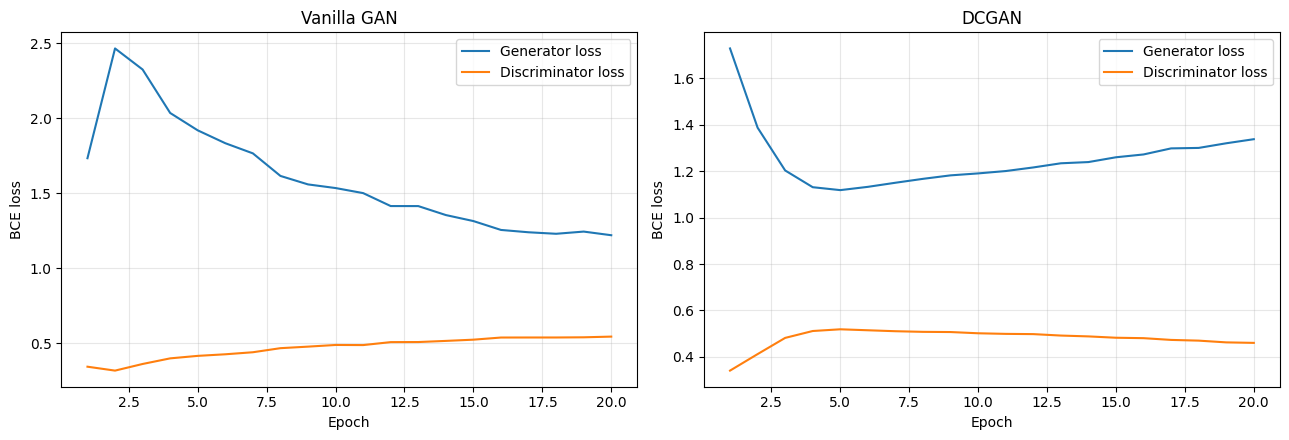

Loss figure saved: /content/drive/MyDrive/Generative_Models_Take_Home/figures/gan_training_losses.png


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

for ax, history, title in [
    (axes[0], history_gan, "Vanilla GAN"),
    (axes[1], history_dcgan, "DCGAN")
]:
    epochs = [r["epoch"] for r in history]
    g_losses = [r["generator_loss"] for r in history]
    d_losses = [r["discriminator_loss"] for r in history]

    ax.plot(epochs, g_losses, label="Generator loss")
    ax.plot(epochs, d_losses, label="Discriminator loss")
    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("BCE loss")
    ax.grid(True, alpha=0.3)
    ax.legend()

plt.tight_layout()

loss_figure_path = FIGURES_DIR / "gan_training_losses.png"
fig.savefig(loss_figure_path, dpi=200, bbox_inches="tight")
plt.show()
plt.close(fig)

print("Loss figure saved:", loss_figure_path)

In [ ]:
import time
import json
import numpy as np
import torch
import torch.nn.functional as F

DDPM_EPOCHS = 20
DDPM_LR = 2e-4
T = DDPM_TIMESTEPS

# Linear variance schedule
betas = torch.linspace(
    1e-4, 0.02, T, device=DEVICE
)
alphas = 1.0 - betas
alpha_bars = torch.cumprod(alphas, dim=0)

# Save the exact schedule for reproducibility.
torch.save(
    {
        "betas": betas.detach().cpu(),
        "alphas": alphas.detach().cpu(),
        "alpha_bars": alpha_bars.detach().cpu(),
        "timesteps": T,
    },
    CHECKPOINT_DIR / "ddpm_schedule.pt"
)


def q_sample(x0, t, noise):
    """
    Forward diffusion:
    x_t = sqrt(alpha_bar_t) * x_0
          + sqrt(1-alpha_bar_t) * epsilon
    """
    alpha_bar_t = alpha_bars[t].view(-1, 1, 1, 1)

    return (
        torch.sqrt(alpha_bar_t) * x0
        + torch.sqrt(1.0 - alpha_bar_t) * noise
    )


def train_ddpm(model, epochs=DDPM_EPOCHS):
    model = model.to(DEVICE)
    optimizer = torch.optim.Adam(
        model.parameters(), lr=DDPM_LR
    )

    history = []
    total_start = time.perf_counter()

    for epoch in range(1, epochs + 1):
        sync_device()
        epoch_start = time.perf_counter()

        model.train()
        train_losses = []

        for x, _ in train_loader:
            x = x.to(DEVICE, non_blocking=True)

            # Match diffusion's standard image range [-1, 1].
            x0 = x * 2.0 - 1.0

            batch = x0.size(0)
            t = torch.randint(
                0, T, (batch,), device=DEVICE
            )
            noise = torch.randn_like(x0)
            xt = q_sample(x0, t, noise)

            predicted_noise = model(xt, t)
            loss = ddpm_noise_loss(predicted_noise, noise)

            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            optimizer.step()

            train_losses.append(loss.item())

        # Validation: evaluate noise-prediction loss on held-out data.
        model.eval()
        val_losses = []

        with torch.no_grad():
            for x, _ in val_loader:
                x = x.to(DEVICE, non_blocking=True)
                x0 = x * 2.0 - 1.0

                batch = x0.size(0)
                t = torch.randint(
                    0, T, (batch,), device=DEVICE
                )
                noise = torch.randn_like(x0)
                xt = q_sample(x0, t, noise)

                predicted_noise = model(xt, t)
                val_loss = ddpm_noise_loss(
                    predicted_noise, noise
                )
                val_losses.append(val_loss.item())

        sync_device()
        epoch_seconds = time.perf_counter() - epoch_start

        record = {
            "epoch": epoch,
            "train_loss": float(np.mean(train_losses)),
            "val_loss": float(np.mean(val_losses)),
            "epoch_time_seconds": float(epoch_seconds),
        }
        history.append(record)

        save_checkpoint(
            model,
            optimizer,
            "ddpm",
            epoch,
            history,
            extra={
                "timesteps": T,
                "beta_start": 1e-4,
                "beta_end": 0.02,
                "learning_rate": DDPM_LR,
                "image_range": [-1, 1],
            }
        )

        save_epoch_history("ddpm", history)

        print(
            f"ddpm | Epoch {epoch:02d}/{epochs} | "
            f"Train: {record['train_loss']:.5f} | "
            f"Val: {record['val_loss']:.5f} | "
            f"Time: {epoch_seconds:.2f}s"
        )

    sync_device()
    total_seconds = time.perf_counter() - total_start

    summary = finish_training_log(
        "ddpm", history, total_seconds
    )

    print("\nDDPM training completed.")
    print(f"Total time: {total_seconds:.2f}s")
    print(f"Mean epoch: {summary['mean_epoch_seconds']:.2f}s")
    print("Checkpoint:", CHECKPOINT_DIR / "ddpm.pt")

    return model, history


ddpm_model, history_ddpm = train_ddpm(
    DDPMNoisePredictor(),
    epochs=DDPM_EPOCHS
)

print("\nSTEP 4E COMPLETE")


ddpm | Epoch 01/20 | Train: 0.24185 | Val: 0.17461 | Time: 14.61s
ddpm | Epoch 02/20 | Train: 0.16643 | Val: 0.15894 | Time: 15.60s
ddpm | Epoch 03/20 | Train: 0.15143 | Val: 0.14919 | Time: 14.73s
ddpm | Epoch 04/20 | Train: 0.14500 | Val: 0.14254 | Time: 14.24s
ddpm | Epoch 05/20 | Train: 0.14073 | Val: 0.14052 | Time: 14.21s
ddpm | Epoch 06/20 | Train: 0.13768 | Val: 0.13821 | Time: 14.30s
ddpm | Epoch 07/20 | Train: 0.13614 | Val: 0.13333 | Time: 14.35s
ddpm | Epoch 08/20 | Train: 0.13457 | Val: 0.13343 | Time: 14.59s
ddpm | Epoch 09/20 | Train: 0.13289 | Val: 0.13051 | Time: 14.37s
ddpm | Epoch 10/20 | Train: 0.13260 | Val: 0.13232 | Time: 14.44s
ddpm | Epoch 11/20 | Train: 0.13204 | Val: 0.13111 | Time: 14.32s
ddpm | Epoch 12/20 | Train: 0.13030 | Val: 0.12660 | Time: 14.74s
ddpm | Epoch 13/20 | Train: 0.12970 | Val: 0.13231 | Time: 14.33s
ddpm | Epoch 14/20 | Train: 0.12926 | Val: 0.12854 | Time: 14.42s
ddpm | Epoch 15/20 | Train: 0.12975 | Val: 0.13016 | Time: 14.34s
ddpm | Epo

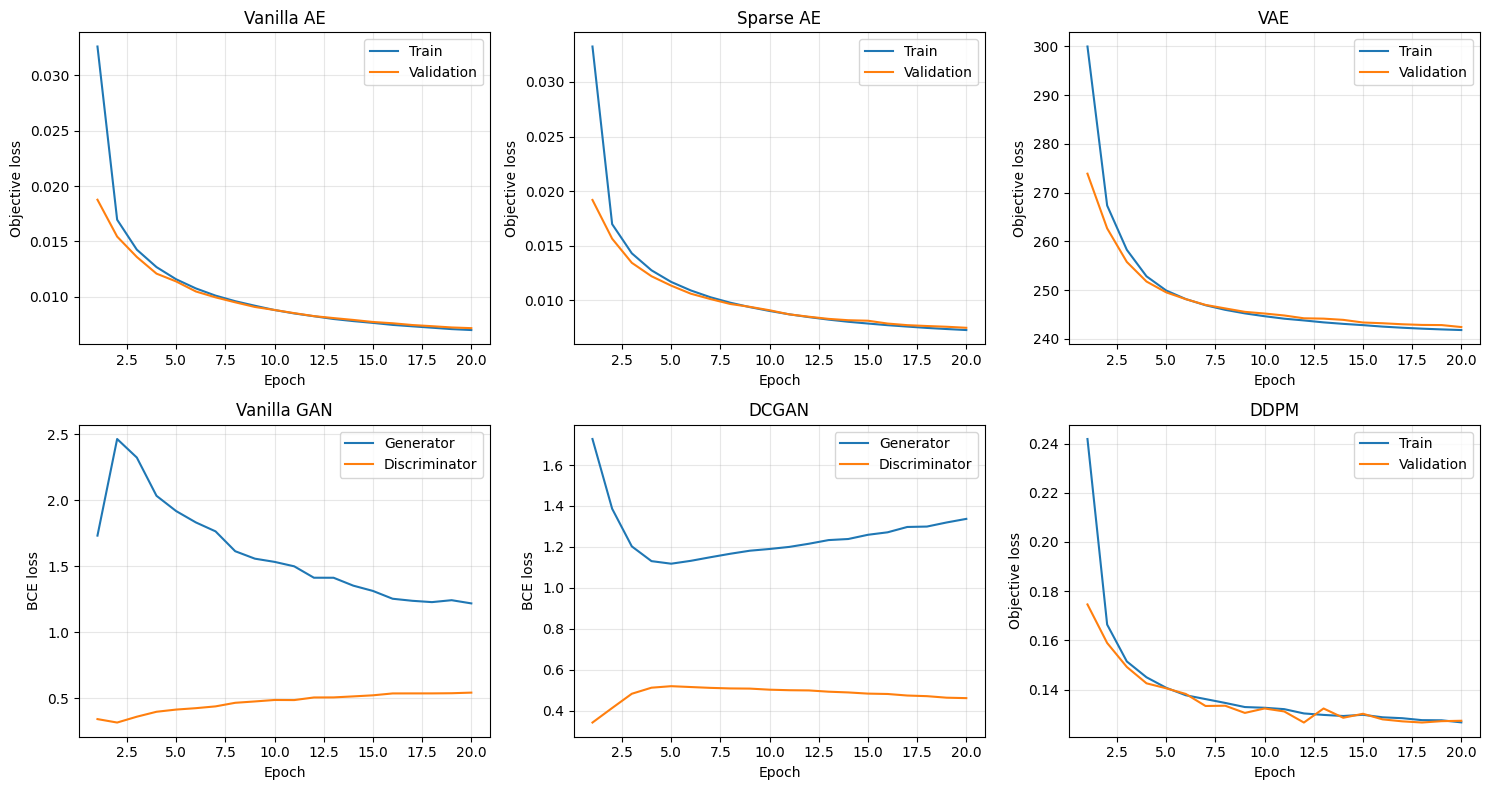

Saved: /content/drive/MyDrive/Generative_Models_Take_Home/figures/figure5_training_loss_curves.png


In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

# Reconstruction models and DDPM
for ax, history, title in [
    (axes[0, 0], history_ae, "Vanilla AE"),
    (axes[0, 1], history_sparse, "Sparse AE"),
    (axes[0, 2], history_vae, "VAE"),
    (axes[1, 2], history_ddpm, "DDPM"),
]:
    epochs = [r["epoch"] for r in history]
    train_values = [r["train_loss"] for r in history]
    val_values = [r["val_loss"] for r in history]

    ax.plot(epochs, train_values, label="Train")
    ax.plot(epochs, val_values, label="Validation")
    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Objective loss")
    ax.grid(True, alpha=0.3)
    ax.legend()

# Sparse AE's history has the same train_loss/val_loss fields.
# GANs use separate generator and discriminator losses.
for ax, history, title in [
    (axes[1, 0], history_gan, "Vanilla GAN"),
    (axes[1, 1], history_dcgan, "DCGAN"),
]:
    epochs = [r["epoch"] for r in history]
    g = [r["generator_loss"] for r in history]
    d = [r["discriminator_loss"] for r in history]

    ax.plot(epochs, g, label="Generator")
    ax.plot(epochs, d, label="Discriminator")
    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("BCE loss")
    ax.grid(True, alpha=0.3)
    ax.legend()

plt.tight_layout()

combined_path = FIGURES_DIR / "figure5_training_loss_curves.png"
fig.savefig(combined_path, dpi=250, bbox_inches="tight")
plt.show()
plt.close(fig)

print("Saved:", combined_path)

In [ ]:
import numpy as np
import pandas as pd
import torch
from skimage.metrics import structural_similarity

def calculate_reconstruction_metrics(model, model_type, loader):
    model.eval()

    all_mse = []
    all_psnr = []
    all_ssim = []

    with torch.no_grad():
        for x, _ in loader:
            x = x.to(DEVICE, non_blocking=True)

            if model_type == "vanilla_ae":
                x_hat = model(x)

            elif model_type == "sparse_ae":
                x_hat, _ = model(x)

            elif model_type == "vae":
                mu, logvar = model.encode(x)
                x_hat = model.decode(mu)

            else:
                raise ValueError(f"Unknown model type: {model_type}")

            # All reconstruction metrics use pixel range [0, 1].
            x_hat = x_hat.clamp(0, 1)

            mse_per_image = (
                (x_hat - x).pow(2)
                .flatten(start_dim=1)
                .mean(dim=1)
            )

            psnr_per_image = 10 * torch.log10(
                1.0 / mse_per_image.clamp_min(1e-12)
            )

            original_np = x.squeeze(1).cpu().numpy()
            reconstructed_np = x_hat.squeeze(1).cpu().numpy()

            for i in range(len(original_np)):
                all_ssim.append(
                    structural_similarity(
                        original_np[i],
                        reconstructed_np[i],
                        data_range=1.0
                    )
                )

            all_mse.extend(mse_per_image.cpu().numpy().tolist())
            all_psnr.extend(psnr_per_image.cpu().numpy().tolist())

    return {
        "test_mse": float(np.mean(all_mse)),
        "test_psnr_db": float(np.mean(all_psnr)),
        "test_ssim": float(np.mean(all_ssim)),
        "n_test_images": len(all_mse),
    }


reconstruction_results = {}

reconstruction_results["Vanilla AE"] = (
    calculate_reconstruction_metrics(
        vanilla_ae, "vanilla_ae", test_loader
    )
)

reconstruction_results["Sparse AE"] = (
    calculate_reconstruction_metrics(
        sparse_ae_model, "sparse_ae", test_loader
    )
)

reconstruction_results["VAE"] = (
    calculate_reconstruction_metrics(
        vae_model, "vae", test_loader
    )
)

reconstruction_df = pd.DataFrame.from_dict(
    reconstruction_results, orient="index"
)

print(reconstruction_df.round(5))

reconstruction_csv = METRICS_DIR / "reconstruction_metrics.csv"
reconstruction_df.to_csv(reconstruction_csv)

print("\nSaved:", reconstruction_csv)

            test_mse  test_psnr_db  test_ssim  n_test_images
Vanilla AE   0.00704      22.56535    0.81394           7000
Sparse AE    0.00699      22.60963    0.81574           7000
VAE          0.01349      19.52466    0.70186           7000

Saved: /content/drive/MyDrive/Generative_Models_Take_Home/metrics/reconstruction_metrics.csv


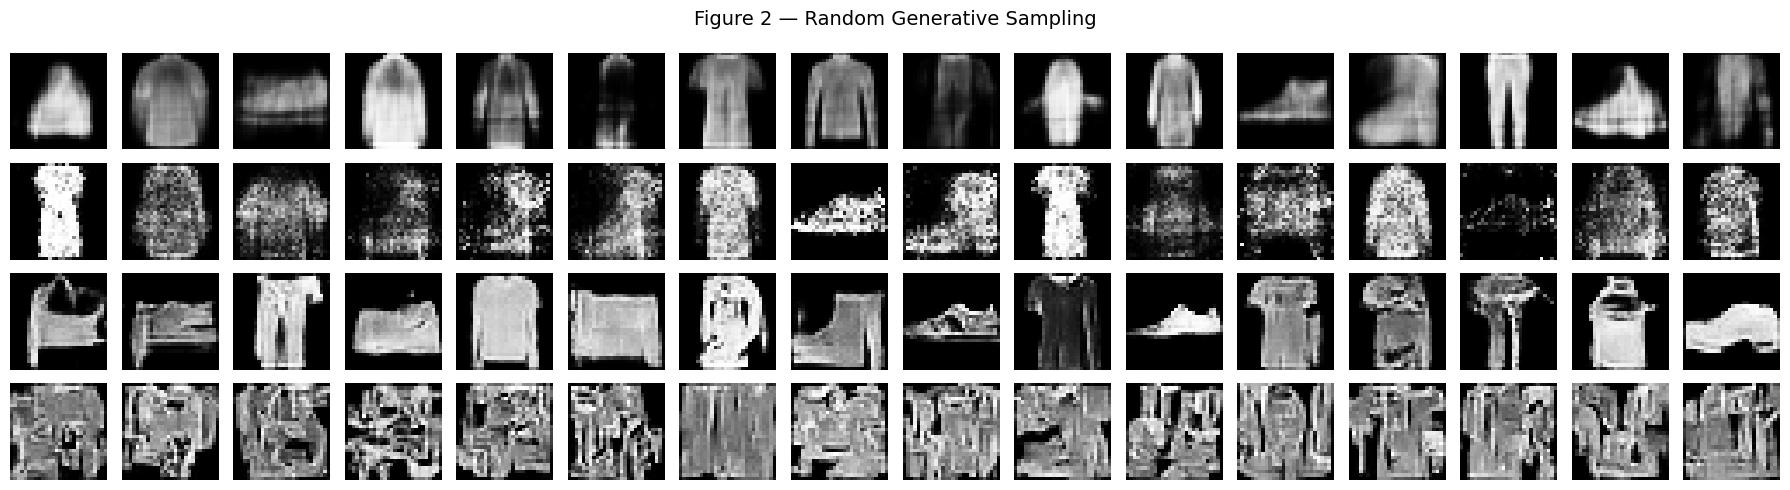

Saved: /content/drive/MyDrive/Generative_Models_Take_Home/figures/figure2_random_sampling.png


In [ ]:
import matplotlib.pyplot as plt
import torch

@torch.no_grad()
def sample_vae(n=16):
    vae_model.eval()
    z = torch.randn(n, LATENT_DIM, device=DEVICE)
    return vae_model.decode(z).clamp(0, 1)


@torch.no_grad()
def sample_vanilla_gan(n=16):
    vanilla_g.eval()
    z = torch.randn(n, GAN_NOISE_DIM, device=DEVICE)
    images = vanilla_g(z)
    return ((images + 1) / 2).clamp(0, 1)


@torch.no_grad()
def sample_dcgan(n=16):
    dcgan_g.eval()
    z = torch.randn(n, DCGAN_NOISE_DIM, device=DEVICE)
    images = dcgan_g(z)
    return ((images + 1) / 2).clamp(0, 1)


@torch.no_grad()
def sample_ddpm(n=16):
    ddpm_model.eval()

    # Start from standard Gaussian noise.
    x = torch.randn(n, 1, 28, 28, device=DEVICE)

    for t_value in reversed(range(T)):
        t = torch.full(
            (n,), t_value, device=DEVICE, dtype=torch.long
        )

        predicted_noise = ddpm_model(x, t)

        alpha_t = alphas[t_value]
        alpha_bar_t = alpha_bars[t_value]
        beta_t = betas[t_value]

        # Mean of the reverse transition.
        x = (
            x - (beta_t / torch.sqrt(1 - alpha_bar_t))
            * predicted_noise
        ) / torch.sqrt(alpha_t)

        if t_value > 0:
            # Stochastic reverse transition.
            x = x + torch.sqrt(beta_t) * torch.randn_like(x)

    # The diffusion process was trained on [-1, 1].
    return ((x + 1) / 2).clamp(0, 1)


sample_sets = {
    "VAE": sample_vae(16),
    "Vanilla GAN": sample_vanilla_gan(16),
    "DCGAN": sample_dcgan(16),
    "DDPM": sample_ddpm(16),
}

fig, axes = plt.subplots(4, 16, figsize=(18, 5))

for row, (model_name, images) in enumerate(sample_sets.items()):
    for col in range(16):
        axes[row, col].imshow(
            images[col, 0].detach().cpu().numpy(),
            cmap="gray",
            vmin=0,
            vmax=1
        )
        axes[row, col].axis("off")

    axes[row, 0].set_ylabel(
        model_name, rotation=90, size="medium", labelpad=25
    )

fig.suptitle("Figure 2 — Random Generative Sampling", fontsize=14)
plt.tight_layout()

sampling_path = FIGURES_DIR / "figure2_random_sampling.png"
fig.savefig(sampling_path, dpi=250, bbox_inches="tight")
plt.show()
plt.close(fig)

print("Saved:", sampling_path)

In [ ]:
import time
import numpy as np
import pandas as pd
import torch

BATCH_EVAL = 64
WARMUP_RUNS = 3
BENCHMARK_RUNS = 15

@torch.no_grad()
def run_inference(model_name):
    if model_name == "Vanilla AE":
        x = torch.rand(BATCH_EVAL, 1, 28, 28, device=DEVICE)
        return vanilla_ae(x)

    elif model_name == "Sparse AE":
        x = torch.rand(BATCH_EVAL, 1, 28, 28, device=DEVICE)
        reconstruction, _ = sparse_ae_model(x)
        return reconstruction

    elif model_name == "VAE":
        z = torch.randn(BATCH_EVAL, LATENT_DIM, device=DEVICE)
        return vae_model.decode(z)

    elif model_name == "Vanilla GAN":
        z = torch.randn(BATCH_EVAL, GAN_NOISE_DIM, device=DEVICE)
        return vanilla_g(z)

    elif model_name == "DCGAN":
        z = torch.randn(BATCH_EVAL, DCGAN_NOISE_DIM, device=DEVICE)
        return dcgan_g(z)

    elif model_name == "DDPM":
        return sample_ddpm(BATCH_EVAL)

    raise ValueError(model_name)


models_to_benchmark = [
    "Vanilla AE", "Sparse AE", "VAE",
    "Vanilla GAN", "DCGAN", "DDPM"
]

latency_results = []

# Put all relevant models in evaluation mode.
for model in [
    vanilla_ae, sparse_ae_model, vae_model,
    vanilla_g, vanilla_d, dcgan_g, dcgan_d, ddpm_model
]:
    model.eval()

for name in models_to_benchmark:
    # Warm-up
    for _ in range(WARMUP_RUNS):
        _ = run_inference(name)

    sync_device()
    timings = []

    for _ in range(BENCHMARK_RUNS):
        sync_device()
        start = time.perf_counter()

        _ = run_inference(name)

        sync_device()
        timings.append((time.perf_counter() - start) * 1000)

    latency_results.append({
        "model": name,
        "batch_size": BATCH_EVAL,
        "mean_latency_ms_batch64": float(np.mean(timings)),
        "std_latency_ms": float(np.std(timings)),
        "latency_ms_per_image": float(np.mean(timings) / BATCH_EVAL),
        "benchmark_repeats": BENCHMARK_RUNS,
        "device": str(DEVICE),
    })

latency_df = pd.DataFrame(latency_results)
print(latency_df.round(3).to_string(index=False))

latency_path = METRICS_DIR / "inference_latency.csv"
latency_df.to_csv(latency_path, index=False)
print("\nSaved:", latency_path)

      model  batch_size  mean_latency_ms_batch64  std_latency_ms  latency_ms_per_image  benchmark_repeats device
 Vanilla AE          64                    0.602           0.285                 0.009                 15   cuda
  Sparse AE          64                    0.789           0.415                 0.012                 15   cuda
        VAE          64                    0.394           0.020                 0.006                 15   cuda
Vanilla GAN          64                    0.534           0.065                 0.008                 15   cuda
      DCGAN          64                    6.336           0.452                 0.099                 15   cuda
       DDPM          64                  518.109          54.216                 8.095                 15   cuda

Saved: /content/drive/MyDrive/Generative_Models_Take_Home/metrics/inference_latency.csv


In [ ]:
%pip -q install torchmetrics torch-fidelity

In [ ]:
import numpy as np
import pandas as pd
import torch
from torchmetrics.image.fid import FrechetInceptionDistance

FID_N = 2048
FID_BATCH_SIZE = 64

def to_rgb_uint8(images):
    """
    Convert grayscale images in [0, 1] to RGB uint8.
    Shape: (B, 1, H, W) -> (B, 3, H, W)
    """
    images = images.clamp(0, 1)
    images = images.repeat(1, 3, 1, 1)
    return (images * 255).round().to(torch.uint8)


@torch.no_grad()
def generate_fid_batch(model_name, n):
    if model_name == "VAE":
        return sample_vae(n)

    elif model_name == "Vanilla GAN":
        return sample_vanilla_gan(n)

    elif model_name == "DCGAN":
        return sample_dcgan(n)

    elif model_name == "DDPM":
        return sample_ddpm(n)

    raise ValueError(model_name)


def calculate_fid_for_model(model_name, real_batches):
    # Each metric instance is independent.
    fid_metric = FrechetInceptionDistance(
        feature=2048,
        normalize=False
    ).to(DEVICE)

    # Add the exact same real test images for each model.
    for real_images in real_batches:
        fid_metric.update(
            to_rgb_uint8(real_images).to(DEVICE),
            real=True
        )

    # Generate an equal number of samples for this model.
    remaining = FID_N

    while remaining > 0:
        n = min(FID_BATCH_SIZE, remaining)

        generated = generate_fid_batch(model_name, n)

        fid_metric.update(
            to_rgb_uint8(generated).to(DEVICE),
            real=False
        )

        remaining -= n

    score = float(fid_metric.compute().item())
    del fid_metric

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return score


# Fixed subset of the test set, reused for every model.
real_batches = []
remaining = FID_N

for images, _ in test_loader:
    if remaining <= 0:
        break

    n = min(images.size(0), remaining)
    real_batches.append(images[:n].to(DEVICE))
    remaining -= n

assert sum(batch.size(0) for batch in real_batches) == FID_N

fid_models = ["VAE", "Vanilla GAN", "DCGAN", "DDPM"]
fid_results = []

for name in fid_models:
    print(f"\nCalculating FID: {name}")

    score = calculate_fid_for_model(name, real_batches)

    fid_results.append({
        "model": name,
        "fid_score": score,
        "real_samples": FID_N,
        "generated_samples": FID_N,
        "feature_extractor": "InceptionV3 / ImageNet",
    })

    print(f"{name} FID: {score:.4f}")

fid_df = pd.DataFrame(fid_results)
fid_path = METRICS_DIR / "fid_metrics.csv"
fid_df.to_csv(fid_path, index=False)

print("\nFID RESULTS")
print(fid_df.to_string(index=False))
print("\nSaved:", fid_path)


Calculating FID: VAE


Downloading: "https://github.com/toshas/torch-fidelity/releases/download/v0.2.0/weights-inception-2015-12-05-6726825d.pth" to /root/.cache/torch/hub/checkpoints/weights-inception-2015-12-05-6726825d.pth
100%|██████████| 91.2M/91.2M [00:00<00:00, 293MB/s]


VAE FID: 97.1361

Calculating FID: Vanilla GAN
Vanilla GAN FID: 167.5108

Calculating FID: DCGAN
DCGAN FID: 36.8303

Calculating FID: DDPM
DDPM FID: 187.7433

FID RESULTS
      model  fid_score  real_samples  generated_samples      feature_extractor
        VAE  97.136063          2048               2048 InceptionV3 / ImageNet
Vanilla GAN 167.510834          2048               2048 InceptionV3 / ImageNet
      DCGAN  36.830292          2048               2048 InceptionV3 / ImageNet
       DDPM 187.743317          2048               2048 InceptionV3 / ImageNet

Saved: /content/drive/MyDrive/Generative_Models_Take_Home/metrics/fid_metrics.csv


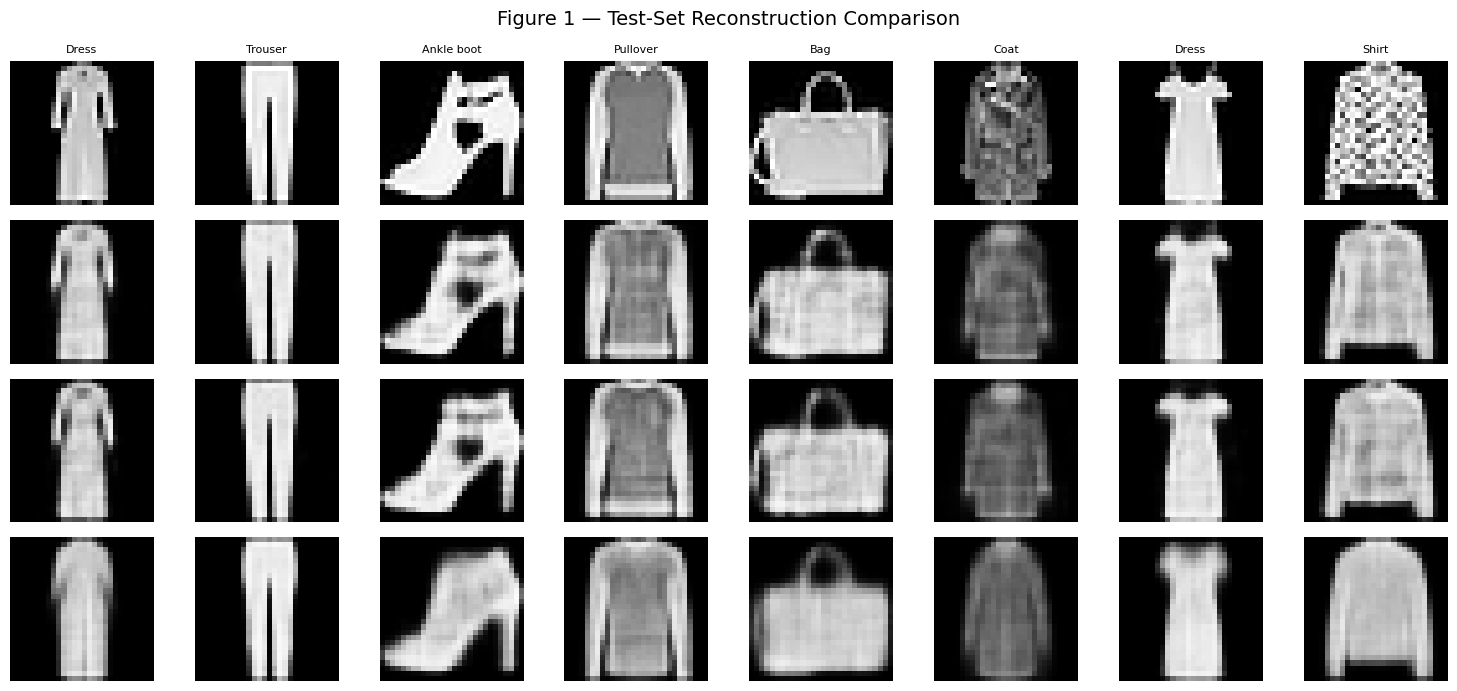

Saved: /content/drive/MyDrive/Generative_Models_Take_Home/figures/figure1_reconstruction.png


In [ ]:
import matplotlib.pyplot as plt
import torch

@torch.no_grad()
def reconstruct_for_figure(model, model_type, images):
    model.eval()

    if model_type == "vanilla_ae":
        return model(images)

    if model_type == "sparse_ae":
        reconstruction, _ = model(images)
        return reconstruction

    if model_type == "vae":
        mu, _ = model.encode(images)
        return model.decode(mu)

    raise ValueError(model_type)


# Obtain 8 fixed examples from the test set.
images, labels = next(iter(test_loader))
images = images[:8].to(DEVICE)
labels = labels[:8].cpu().tolist()

reconstructions = {
    "Vanilla AE": reconstruct_for_figure(
        vanilla_ae, "vanilla_ae", images
    ),
    "Sparse AE": reconstruct_for_figure(
        sparse_ae_model, "sparse_ae", images
    ),
    "VAE": reconstruct_for_figure(
        vae_model, "vae", images
    ),
}

fig, axes = plt.subplots(4, 8, figsize=(15, 7))

# Row 1: original images.
for col in range(8):
    axes[0, col].imshow(
        images[col, 0].cpu(), cmap="gray", vmin=0, vmax=1
    )
    axes[0, col].set_title(CLASS_NAMES[labels[col]], fontsize=8)
    axes[0, col].axis("off")

row_models = [
    ("Vanilla AE", reconstructions["Vanilla AE"]),
    ("Sparse AE", reconstructions["Sparse AE"]),
    ("VAE", reconstructions["VAE"]),
]

for row, (name, batch) in enumerate(row_models, start=1):
    for col in range(8):
        axes[row, col].imshow(
            batch[col, 0].clamp(0, 1).cpu(),
            cmap="gray",
            vmin=0,
            vmax=1
        )
        axes[row, col].axis("off")

row_labels = [
    "Original",
    "Vanilla AE",
    "Sparse AE",
    "VAE"
]

for row, name in enumerate(row_labels):
    axes[row, 0].set_ylabel(
        name, rotation=90, size="medium", labelpad=25
    )

fig.suptitle(
    "Figure 1 — Test-Set Reconstruction Comparison",
    fontsize=14
)
plt.tight_layout()

figure1_path = FIGURES_DIR / "figure1_reconstruction.png"
fig.savefig(figure1_path, dpi=250, bbox_inches="tight")
plt.show()
plt.close(fig)

print("Saved:", figure1_path)

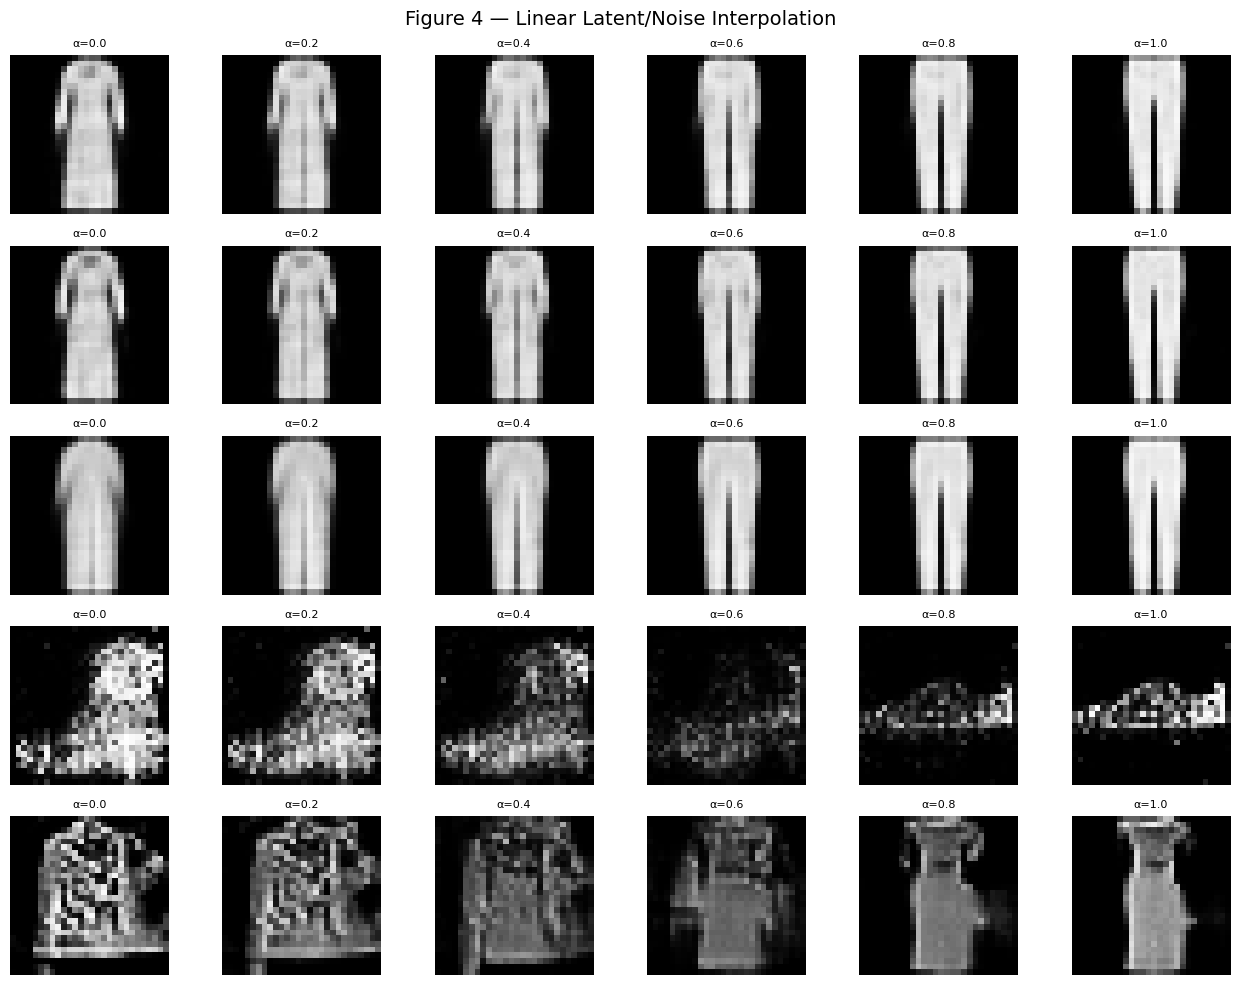

Figure 4 saved: /content/drive/MyDrive/Generative_Models_Take_Home/figures/figure4_latent_interpolation.png


In [ ]:
import matplotlib.pyplot as plt
import torch

ALPHAS = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]

@torch.no_grad()
def make_interpolation_figure():
    # Select two fixed test images.
    test_images, test_labels = next(iter(test_loader))
    x_a = test_images[0:1].to(DEVICE)
    x_b = test_images[1:2].to(DEVICE)

    # Encode images into latent representations.
    z_a_ae = vanilla_ae.encode(x_a)
    z_b_ae = vanilla_ae.encode(x_b)

    z_a_sparse = sparse_ae_model.encode(x_a)
    z_b_sparse = sparse_ae_model.encode(x_b)

    mu_a, _ = vae_model.encode(x_a)
    mu_b, _ = vae_model.encode(x_b)

    # GANs have no encoder in our implementation.
    # Interpolate between two random prior noise vectors.
    z_a_gan = torch.randn(1, GAN_NOISE_DIM, device=DEVICE)
    z_b_gan = torch.randn(1, GAN_NOISE_DIM, device=DEVICE)

    z_a_dcgan = torch.randn(1, DCGAN_NOISE_DIM, device=DEVICE)
    z_b_dcgan = torch.randn(1, DCGAN_NOISE_DIM, device=DEVICE)

    fig, axes = plt.subplots(5, 6, figsize=(13, 10))

    for col, alpha in enumerate(ALPHAS):
        # Linear interpolation in latent/noise space.
        z_ae = (1 - alpha) * z_a_ae + alpha * z_b_ae
        z_sparse = (
            (1 - alpha) * z_a_sparse + alpha * z_b_sparse
        )
        z_vae = (1 - alpha) * mu_a + alpha * mu_b
        z_gan = (1 - alpha) * z_a_gan + alpha * z_b_gan
        z_dcgan = (
            (1 - alpha) * z_a_dcgan + alpha * z_b_dcgan
        )

        generated_images = [
            vanilla_ae.decode(z_ae),
            sparse_ae_model.decode(z_sparse),
            vae_model.decode(z_vae),
            vanilla_g(z_gan),
            dcgan_g(
                z_dcgan.view(1, DCGAN_NOISE_DIM, 1, 1)
            ),
        ]

        for row, generated in enumerate(generated_images):
            generated = generated.detach()

            # GAN/DCGAN output is in [-1, 1].
            if row in (3, 4):
                generated = (generated + 1.0) / 2.0

            image = (
                generated[0, 0]
                .clamp(0, 1)
                .cpu()
                .numpy()
            )

            axes[row, col].imshow(
                image, cmap="gray", vmin=0, vmax=1
            )
            axes[row, col].set_title(
                f"α={alpha:.1f}", fontsize=8
            )
            axes[row, col].axis("off")

    row_names = [
        "Vanilla AE", "Sparse AE", "VAE",
        "Vanilla GAN", "DCGAN"
    ]

    for row, name in enumerate(row_names):
        axes[row, 0].set_ylabel(
            name, rotation=90, size="medium", labelpad=25
        )

    fig.suptitle(
        "Figure 4 — Linear Latent/Noise Interpolation",
        fontsize=14
    )
    plt.tight_layout()

    output_path = FIGURES_DIR / "figure4_latent_interpolation.png"
    fig.savefig(output_path, dpi=250, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    print("Figure 4 saved:", output_path)


make_interpolation_figure()

Epoch 01/30 | Train loss: 0.5797 | Val loss: 0.4371 | Val acc: 84.1714% | Time: 11.48s
Epoch 02/30 | Train loss: 0.3935 | Val loss: 0.3909 | Val acc: 85.6857% | Time: 7.59s
Epoch 03/30 | Train loss: 0.3524 | Val loss: 0.3774 | Val acc: 86.0000% | Time: 7.74s
Epoch 04/30 | Train loss: 0.3253 | Val loss: 0.3588 | Val acc: 87.1857% | Time: 7.64s
Epoch 05/30 | Train loss: 0.3036 | Val loss: 0.3574 | Val acc: 86.8714% | Time: 7.79s
Epoch 06/30 | Train loss: 0.2914 | Val loss: 0.3359 | Val acc: 87.6857% | Time: 7.70s
Epoch 07/30 | Train loss: 0.2756 | Val loss: 0.3450 | Val acc: 87.3714% | Time: 7.63s
Epoch 08/30 | Train loss: 0.2652 | Val loss: 0.3193 | Val acc: 88.0714% | Time: 7.81s
Epoch 09/30 | Train loss: 0.2531 | Val loss: 0.3199 | Val acc: 88.5286% | Time: 8.02s
Epoch 10/30 | Train loss: 0.2430 | Val loss: 0.3113 | Val acc: 88.8286% | Time: 8.29s
Epoch 11/30 | Train loss: 0.2308 | Val loss: 0.3225 | Val acc: 88.6000% | Time: 7.63s
Epoch 12/30 | Train loss: 0.2245 | Val loss: 0.3135 |

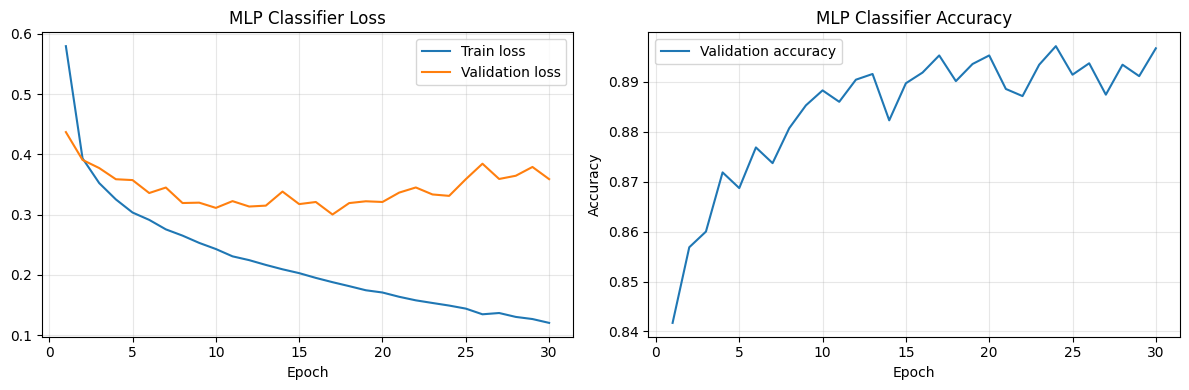


Classifier training time: 242.03 seconds
Test accuracy: 89.79 %
Figure saved: /content/drive/MyDrive/Generative_Models_Take_Home/figures/mlp_classifier_training.png
STEP 8A COMPLETE


In [ ]:
import time
import json
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

from sklearn.metrics import accuracy_score, classification_report

CLASSIFIER_EPOCHS = 30
CLASSIFIER_LR = 1e-3

class FashionMLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(28 * 28, 256)
        self.fc2 = nn.Linear(256, 128)
        self.fc3 = nn.Linear(128, 10)

    def forward(self, x):
        x = self.flatten(x)
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        return self.fc3(x)


@torch.no_grad()
def evaluate_classifier(model, loader):
    model.eval()
    all_preds = []
    all_labels = []
    losses = []

    for x, y in loader:
        x = x.to(DEVICE, non_blocking=True)
        y = y.to(DEVICE, non_blocking=True)

        logits = model(x)
        loss = F.cross_entropy(logits, y)

        preds = logits.argmax(dim=1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(y.cpu().numpy())
        losses.append(loss.item())

    accuracy = accuracy_score(all_labels, all_preds)

    return (
        float(np.mean(losses)),
        float(accuracy),
        np.array(all_labels),
        np.array(all_preds)
    )


classifier = FashionMLP().to(DEVICE)
classifier_optimizer = torch.optim.Adam(
    classifier.parameters(),
    lr=CLASSIFIER_LR
)

classifier_history = []
classifier_start = time.perf_counter()

for epoch in range(1, CLASSIFIER_EPOCHS + 1):
    sync_device()
    epoch_start = time.perf_counter()

    classifier.train()
    train_losses = []

    for x, y in train_loader:
        x = x.to(DEVICE, non_blocking=True)
        y = y.to(DEVICE, non_blocking=True)

        classifier_optimizer.zero_grad(set_to_none=True)
        logits = classifier(x)
        loss = F.cross_entropy(logits, y)
        loss.backward()
        classifier_optimizer.step()

        train_losses.append(loss.item())

    val_loss, val_accuracy, _, _ = evaluate_classifier(
        classifier, val_loader
    )

    sync_device()
    epoch_seconds = time.perf_counter() - epoch_start

    record = {
        "epoch": epoch,
        "train_loss": float(np.mean(train_losses)),
        "val_loss": val_loss,
        "val_accuracy": val_accuracy,
        "epoch_time_seconds": float(epoch_seconds)
    }
    classifier_history.append(record)

    # Persist checkpoint and history every epoch.
    save_checkpoint(
        classifier,
        classifier_optimizer,
        "mlp_classifier",
        epoch,
        classifier_history,
        extra={
            "architecture": "784-256-128-10",
            "learning_rate": CLASSIFIER_LR
        }
    )
    save_epoch_history("mlp_classifier", classifier_history)

    print(
        f"Epoch {epoch:02d}/{CLASSIFIER_EPOCHS} | "
        f"Train loss: {record['train_loss']:.4f} | "
        f"Val loss: {val_loss:.4f} | "
        f"Val acc: {val_accuracy:.4%} | "
        f"Time: {epoch_seconds:.2f}s"
    )

sync_device()
classifier_total_seconds = time.perf_counter() - classifier_start

test_loss, test_accuracy, y_true, y_pred = evaluate_classifier(
    classifier, test_loader
)

classifier_summary = {
    "test_accuracy": test_accuracy,
    "test_loss": test_loss,
    "total_training_seconds": float(classifier_total_seconds),
    "mean_epoch_seconds": float(np.mean([
        r["epoch_time_seconds"] for r in classifier_history
    ])),
    "epochs_completed": len(classifier_history)
}

save_json(
    classifier_summary,
    LOG_DIR / "mlp_classifier_summary.json"
)

print("\nCLASSIFIER RESULTS")
print(json.dumps(classifier_summary, indent=2))

print("\nClassification report:")
print(classification_report(
    y_true, y_pred,
    target_names=CLASS_NAMES,
    digits=4
))

# Plot classifier training history.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

epochs = [r["epoch"] for r in classifier_history]
train_loss_values = [r["train_loss"] for r in classifier_history]
val_loss_values = [r["val_loss"] for r in classifier_history]
val_acc_values = [r["val_accuracy"] for r in classifier_history]

axes[0].plot(epochs, train_loss_values, label="Train loss")
axes[0].plot(epochs, val_loss_values, label="Validation loss")
axes[0].set_title("MLP Classifier Loss")
axes[0].set_xlabel("Epoch")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(epochs, val_acc_values, label="Validation accuracy")
axes[1].set_title("MLP Classifier Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()

classifier_figure_path = FIGURES_DIR / "mlp_classifier_training.png"
fig.savefig(classifier_figure_path, dpi=250, bbox_inches="tight")
plt.show()
plt.close(fig)

print("\nClassifier training time:", round(classifier_total_seconds, 2), "seconds")
print("Test accuracy:", round(test_accuracy * 100, 2), "%")
print("Figure saved:", classifier_figure_path)
print("STEP 8A COMPLETE")

In [ ]:
import time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

from sklearn.metrics import accuracy_score, classification_report

MLP_LATENT_DIM = 64
MLP_EPOCHS = 30
MLP_LR = 1e-3

class FashionMLP64(nn.Module):
    def __init__(self):
        super().__init__()
        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(784, 256)  # W1
        self.fc2 = nn.Linear(256, 64)   # W2; z_MLP
        self.fc3 = nn.Linear(64, 10)    # W3

    def extract_latent(self, x):
        h1 = F.relu(self.fc1(self.flatten(x)))
        z = F.relu(self.fc2(h1))
        return z

    def forward(self, x):
        z = self.extract_latent(x)
        return self.fc3(z)


@torch.no_grad()
def evaluate_mlp64(model, loader):
    model.eval()
    losses, all_preds, all_labels = [], [], []

    for x, y in loader:
        x = x.to(DEVICE, non_blocking=True)
        y = y.to(DEVICE, non_blocking=True)

        logits = model(x)
        losses.append(F.cross_entropy(logits, y).item())

        all_preds.extend(logits.argmax(1).cpu().numpy())
        all_labels.extend(y.cpu().numpy())

    return (
        float(np.mean(losses)),
        float(accuracy_score(all_labels, all_preds)),
        np.asarray(all_labels),
        np.asarray(all_preds)
    )


mlp64 = FashionMLP64().to(DEVICE)
mlp64_optimizer = torch.optim.Adam(mlp64.parameters(), lr=MLP_LR)

mlp64_history = []
mlp64_start = time.perf_counter()

for epoch in range(1, MLP_EPOCHS + 1):
    sync_device()
    epoch_start = time.perf_counter()

    mlp64.train()
    train_losses = []

    for x, y in train_loader:
        x = x.to(DEVICE, non_blocking=True)
        y = y.to(DEVICE, non_blocking=True)

        mlp64_optimizer.zero_grad(set_to_none=True)
        loss = F.cross_entropy(mlp64(x), y)
        loss.backward()
        mlp64_optimizer.step()

        train_losses.append(loss.item())

    val_loss, val_acc, _, _ = evaluate_mlp64(mlp64, val_loader)

    sync_device()
    epoch_seconds = time.perf_counter() - epoch_start

    mlp64_history.append({
        "epoch": epoch,
        "train_loss": float(np.mean(train_losses)),
        "val_loss": val_loss,
        "val_accuracy": val_acc,
        "epoch_time_seconds": float(epoch_seconds)
    })

    # Use a distinct checkpoint name to preserve the earlier experiment.
    save_checkpoint(
        mlp64,
        mlp64_optimizer,
        "mlp_classifier_64",
        epoch,
        mlp64_history,
        extra={
            "architecture": "784-256-64-10",
            "latent_dim": 64,
            "learning_rate": MLP_LR
        }
    )
    save_epoch_history("mlp_classifier_64", mlp64_history)

    print(
        f"Epoch {epoch:02d}/{MLP_EPOCHS} | "
        f"Train: {np.mean(train_losses):.4f} | "
        f"Val: {val_loss:.4f} | "
        f"Val acc: {val_acc:.4%} | "
        f"Time: {epoch_seconds:.2f}s"
    )

sync_device()
mlp64_total_seconds = time.perf_counter() - mlp64_start

mlp64_test_loss, mlp64_test_acc, y_true64, y_pred64 = (
    evaluate_mlp64(mlp64, test_loader)
)

mlp64_summary = {
    "architecture": "784-256-64-10",
    "latent_dim": 64,
    "test_accuracy": mlp64_test_acc,
    "test_loss": mlp64_test_loss,
    "total_training_seconds": float(mlp64_total_seconds),
    "mean_epoch_seconds": float(np.mean([
        r["epoch_time_seconds"] for r in mlp64_history
    ])),
    "epochs_completed": len(mlp64_history)
}

save_json(
    mlp64_summary,
    LOG_DIR / "mlp_classifier_64_summary.json"
)

print("\nSPEC-COMPLIANT MLP RESULTS")
print(mlp64_summary)
print("\nClassification report:")
print(classification_report(
    y_true64, y_pred64,
    target_names=CLASS_NAMES,
    digits=4
))

# Verify latent dimensionality.
with torch.no_grad():
    test_batch, _ = next(iter(test_loader))
    latent_batch = mlp64.extract_latent(test_batch[:8].to(DEVICE))

assert latent_batch.shape == (8, 64)
print("\nLatent shape verified:", tuple(latent_batch.shape))
print("Test accuracy:", round(mlp64_test_acc * 100, 2), "%")
print("STEP 8B COMPLETE")

Epoch 01/30 | Train: 0.6095 | Val: 0.4436 | Val acc: 83.9143% | Time: 11.91s
Epoch 02/30 | Train: 0.4105 | Val: 0.4058 | Val acc: 85.0571% | Time: 8.13s
Epoch 03/30 | Train: 0.3661 | Val: 0.3709 | Val acc: 86.3286% | Time: 8.05s
Epoch 04/30 | Train: 0.3382 | Val: 0.3979 | Val acc: 85.2571% | Time: 7.91s
Epoch 05/30 | Train: 0.3185 | Val: 0.3494 | Val acc: 87.4571% | Time: 8.06s
Epoch 06/30 | Train: 0.3022 | Val: 0.3452 | Val acc: 87.3000% | Time: 8.20s
Epoch 07/30 | Train: 0.2872 | Val: 0.3386 | Val acc: 87.7000% | Time: 7.88s
Epoch 08/30 | Train: 0.2764 | Val: 0.3298 | Val acc: 87.6143% | Time: 7.97s
Epoch 09/30 | Train: 0.2644 | Val: 0.3220 | Val acc: 88.2857% | Time: 8.46s
Epoch 10/30 | Train: 0.2517 | Val: 0.3186 | Val acc: 88.3571% | Time: 8.01s
Epoch 11/30 | Train: 0.2460 | Val: 0.3364 | Val acc: 88.1857% | Time: 7.96s
Epoch 12/30 | Train: 0.2359 | Val: 0.3186 | Val acc: 88.5286% | Time: 7.94s
Epoch 13/30 | Train: 0.2273 | Val: 0.3353 | Val acc: 88.3714% | Time: 8.58s
Epoch 14/30

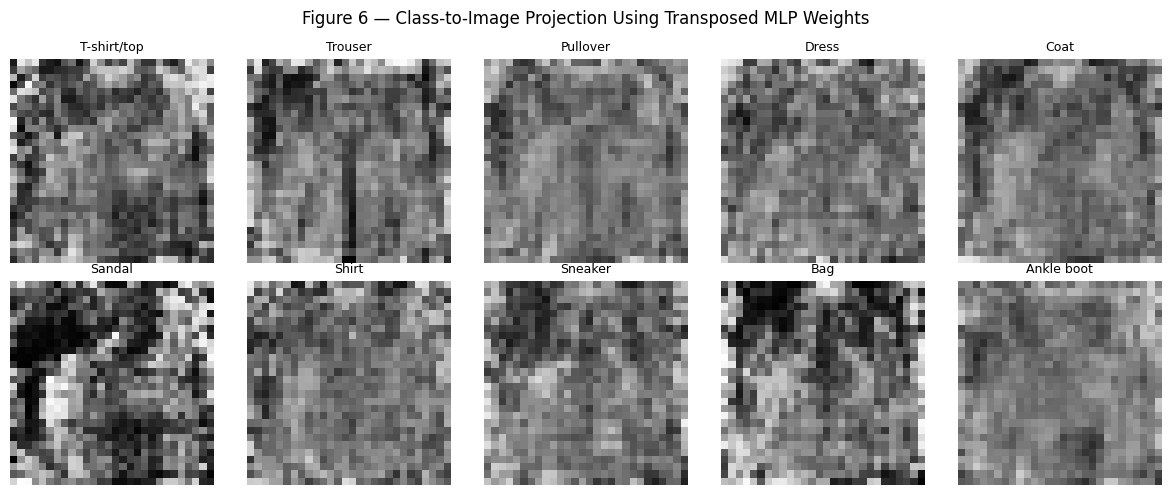

Projection tensor shape: (10, 28, 28)
Saved: /content/drive/MyDrive/Generative_Models_Take_Home/figures/figure6_mlp_transpose_projection.png
STEP 9 COMPLETE


In [ ]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

# Model: 784 -> 256 -> 64 -> 10
# Forward:
# h1 = ReLU(x W1^T + b1)
# z  = ReLU(h1 W2^T + b2)
# y  = z W3^T + b3
#
# Backward approximation required by the assignment:
# z_hat  = ReLU(y_onehot W3)
# h1_hat = ReLU(z_hat W2)
# x_hat  = sigmoid(h1_hat W1)

@torch.no_grad()
def transpose_weight_projection(model, num_classes=10):
    model.eval()
    results = []

    for class_id in range(num_classes):
        # One-hot class vector, shape (1, 10).
        y_onehot = F.one_hot(
            torch.tensor([class_id], device=DEVICE),
            num_classes=10
        ).float()

        # Reverse projection using transposed forward weights.
        z_hat = F.relu(y_onehot @ model.fc3.weight)
        h1_hat = F.relu(z_hat @ model.fc2.weight)
        x_hat = torch.sigmoid(h1_hat @ model.fc1.weight)

        results.append(x_hat.reshape(28, 28).cpu())

    return torch.stack(results)


class_projection = transpose_weight_projection(mlp64)

fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for class_id, ax in enumerate(axes.flat):
    ax.imshow(class_projection[class_id], cmap="gray", vmin=0, vmax=1)
    ax.set_title(CLASS_NAMES[class_id], fontsize=9)
    ax.axis("off")

fig.suptitle(
    "Figure 6 — Class-to-Image Projection Using Transposed MLP Weights"
)
plt.tight_layout()

projection_path = FIGURES_DIR / "figure6_mlp_transpose_projection.png"
fig.savefig(projection_path, dpi=250, bbox_inches="tight")
plt.show()
plt.close(fig)

print("Projection tensor shape:", tuple(class_projection.shape))
print("Saved:", projection_path)
print("STEP 9 COMPLETE")

In [ ]:
import time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

DECODER_EPOCHS = 20
DECODER_LR = 1e-3

# Freeze the classifier. Only the decoder will be optimized.
mlp64.eval()
for parameter in mlp64.parameters():
    parameter.requires_grad_(False)


class FrozenLatentDecoder(nn.Module):
    """
    Maps a 64-dimensional MLP representation back to 28x28 pixels.
    Architecture: 64 -> 256 -> 784.
    """
    def __init__(self, latent_dim=64):
        super().__init__()
        self.fc1 = nn.Linear(latent_dim, 256)
        self.fc2 = nn.Linear(256, 784)

    def forward(self, z):
        x = F.relu(self.fc1(z))
        x = torch.sigmoid(self.fc2(x))
        return x.view(-1, 1, 28, 28)


frozen_decoder = FrozenLatentDecoder(
    latent_dim=MLP_LATENT_DIM
).to(DEVICE)

decoder_optimizer = torch.optim.Adam(
    frozen_decoder.parameters(),
    lr=DECODER_LR
)

decoder_history = []
decoder_start = time.perf_counter()

for epoch in range(1, DECODER_EPOCHS + 1):
    sync_device()
    epoch_start = time.perf_counter()

    frozen_decoder.train()
    train_losses = []

    for x, _ in train_loader:
        x = x.to(DEVICE, non_blocking=True)

        # Extract features without updating classifier parameters.
        with torch.no_grad():
            z = mlp64.extract_latent(x)

        reconstruction = frozen_decoder(z)
        loss = F.mse_loss(reconstruction, x)

        decoder_optimizer.zero_grad(set_to_none=True)
        loss.backward()
        decoder_optimizer.step()

        train_losses.append(loss.item())

    # Validation reconstruction loss.
    frozen_decoder.eval()
    val_losses = []

    with torch.no_grad():
        for x, _ in val_loader:
            x = x.to(DEVICE, non_blocking=True)
            z = mlp64.extract_latent(x)
            reconstruction = frozen_decoder(z)
            val_losses.append(
                F.mse_loss(reconstruction, x).item()
            )

    sync_device()
    epoch_seconds = time.perf_counter() - epoch_start

    record = {
        "epoch": epoch,
        "train_loss": float(np.mean(train_losses)),
        "val_loss": float(np.mean(val_losses)),
        "epoch_time_seconds": float(epoch_seconds)
    }
    decoder_history.append(record)

    save_checkpoint(
        frozen_decoder,
        decoder_optimizer,
        "frozen_latent_decoder",
        epoch,
        decoder_history,
        extra={
            "architecture": "64-256-784",
            "latent_dim": 64,
            "encoder": "frozen MLP classifier 784-256-64-10",
            "loss": "MSE"
        }
    )
    save_epoch_history("frozen_latent_decoder", decoder_history)

    print(
        f"Decoder Epoch {epoch:02d}/{DECODER_EPOCHS} | "
        f"Train MSE: {record['train_loss']:.6f} | "
        f"Val MSE: {record['val_loss']:.6f} | "
        f"Time: {epoch_seconds:.2f}s"
    )

sync_device()
decoder_total_seconds = time.perf_counter() - decoder_start

print("\nFrozen decoder training complete.")
print(f"Total time: {decoder_total_seconds:.2f}s")
print(f"Mean epoch: {np.mean([r['epoch_time_seconds'] for r in decoder_history]):.2f}s")
print("STEP 10A COMPLETE")

Decoder Epoch 01/20 | Train MSE: 0.036131 | Val MSE: 0.026225 | Time: 14.43s
Decoder Epoch 02/20 | Train MSE: 0.024576 | Val MSE: 0.023231 | Time: 12.96s
Decoder Epoch 03/20 | Train MSE: 0.022451 | Val MSE: 0.021863 | Time: 7.84s
Decoder Epoch 04/20 | Train MSE: 0.021283 | Val MSE: 0.020962 | Time: 7.69s
Decoder Epoch 05/20 | Train MSE: 0.020493 | Val MSE: 0.020309 | Time: 7.82s
Decoder Epoch 06/20 | Train MSE: 0.019931 | Val MSE: 0.019923 | Time: 7.74s
Decoder Epoch 07/20 | Train MSE: 0.019513 | Val MSE: 0.019875 | Time: 8.21s
Decoder Epoch 08/20 | Train MSE: 0.019202 | Val MSE: 0.019348 | Time: 7.73s
Decoder Epoch 09/20 | Train MSE: 0.018918 | Val MSE: 0.019062 | Time: 7.82s
Decoder Epoch 10/20 | Train MSE: 0.018658 | Val MSE: 0.018866 | Time: 7.72s
Decoder Epoch 11/20 | Train MSE: 0.018479 | Val MSE: 0.018641 | Time: 7.53s
Decoder Epoch 12/20 | Train MSE: 0.018283 | Val MSE: 0.018561 | Time: 8.06s
Decoder Epoch 13/20 | Train MSE: 0.018159 | Val MSE: 0.018568 | Time: 8.06s
Decoder Ep

Frozen latent decoder test MSE: 0.017732


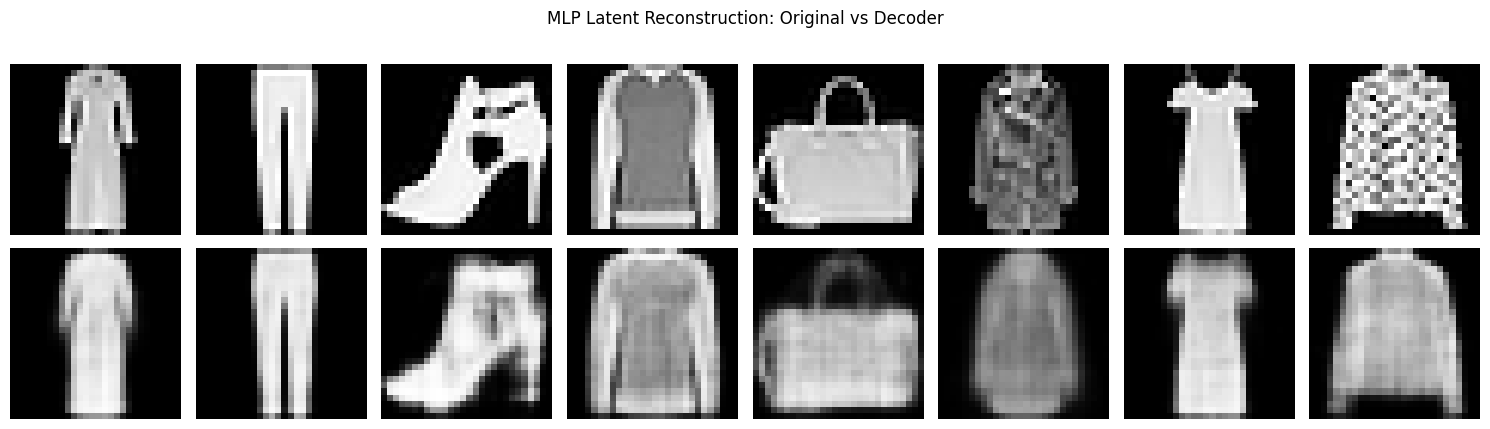

Figure saved: /content/drive/MyDrive/Generative_Models_Take_Home/figures/mlp_frozen_decoder_reconstruction.png
Metrics saved: /content/drive/MyDrive/Generative_Models_Take_Home/metrics/frozen_decoder_metrics.csv
STEP 10B COMPLETE


In [ ]:
import pandas as pd
import torch
import matplotlib.pyplot as plt

@torch.no_grad()
def evaluate_frozen_decoder():
    mlp64.eval()
    frozen_decoder.eval()

    mse_values = []
    example_images = None
    example_reconstructions = None

    for x, _ in test_loader:
        x = x.to(DEVICE, non_blocking=True)
        z = mlp64.extract_latent(x)
        reconstruction = frozen_decoder(z).clamp(0, 1)

        per_image_mse = (
            (reconstruction - x)
            .pow(2)
            .flatten(start_dim=1)
            .mean(dim=1)
        )
        mse_values.extend(per_image_mse.cpu().tolist())

        if example_images is None:
            example_images = x[:8].cpu()
            example_reconstructions = reconstruction[:8].cpu()

    return (
        float(np.mean(mse_values)),
        example_images,
        example_reconstructions
    )


decoder_test_mse, originals, decoder_recons = evaluate_frozen_decoder()

print(f"Frozen latent decoder test MSE: {decoder_test_mse:.6f}")

fig, axes = plt.subplots(2, 8, figsize=(15, 4.5))

for i in range(8):
    axes[0, i].imshow(
        originals[i, 0], cmap="gray", vmin=0, vmax=1
    )
    axes[0, i].axis("off")

    axes[1, i].imshow(
        decoder_recons[i, 0], cmap="gray", vmin=0, vmax=1
    )
    axes[1, i].axis("off")

axes[0, 0].set_ylabel("Original", labelpad=20)
axes[1, 0].set_ylabel("Frozen decoder", labelpad=20)

fig.suptitle("MLP Latent Reconstruction: Original vs Decoder")
plt.tight_layout()

decoder_figure_path = FIGURES_DIR / "mlp_frozen_decoder_reconstruction.png"
fig.savefig(decoder_figure_path, dpi=250, bbox_inches="tight")
plt.show()
plt.close(fig)

decoder_metrics_path = METRICS_DIR / "frozen_decoder_metrics.csv"
pd.DataFrame([{
    "model": "Frozen MLP latent decoder",
    "latent_dim": MLP_LATENT_DIM,
    "test_mse": decoder_test_mse,
    "total_training_seconds": decoder_total_seconds,
    "epochs": DECODER_EPOCHS
}]).to_csv(decoder_metrics_path, index=False)

print("Figure saved:", decoder_figure_path)
print("Metrics saved:", decoder_metrics_path)
print("STEP 10B COMPLETE")

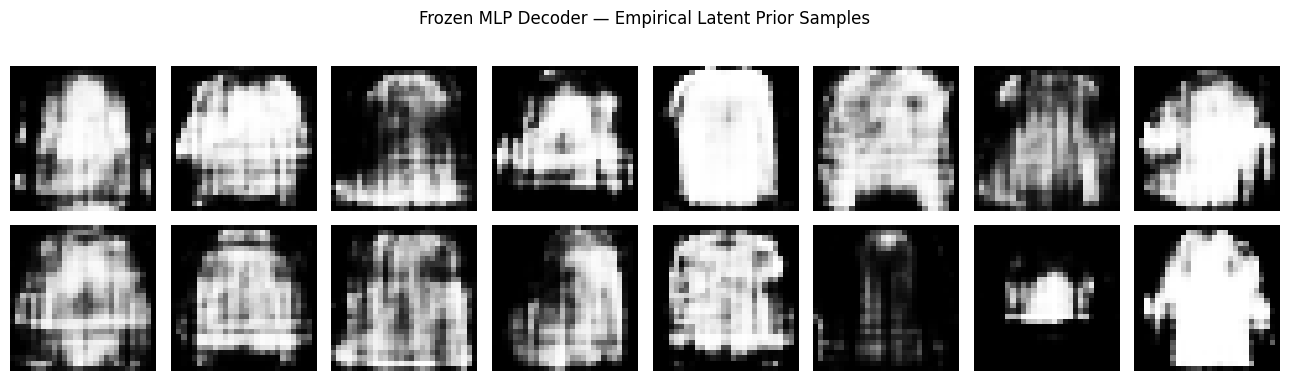

Prior-sampling figure saved: /content/drive/MyDrive/Generative_Models_Take_Home/figures/mlp_frozen_decoder_prior_samples.png
STEP 10C COMPLETE


In [ ]:
@torch.no_grad()
def estimate_latent_statistics(loader):
    mlp64.eval()

    latent_batches = []
    for x, _ in loader:
        x = x.to(DEVICE, non_blocking=True)
        z = mlp64.extract_latent(x)
        latent_batches.append(z.cpu())

    all_z = torch.cat(latent_batches, dim=0)

    mean = all_z.mean(dim=0)
    std = all_z.std(dim=0).clamp_min(1e-4)

    return mean.to(DEVICE), std.to(DEVICE)


@torch.no_grad()
def sample_frozen_decoder(n=16):
    frozen_decoder.eval()

    latent_mean, latent_std = estimate_latent_statistics(train_loader)
    z = latent_mean + latent_std * torch.randn(
        n, MLP_LATENT_DIM, device=DEVICE
    )

    return frozen_decoder(z).clamp(0, 1)


prior_samples = sample_frozen_decoder(16)

fig, axes = plt.subplots(2, 8, figsize=(13, 4))

for i, ax in enumerate(axes.flat):
    ax.imshow(
        prior_samples[i, 0].cpu().numpy(),
        cmap="gray",
        vmin=0,
        vmax=1
    )
    ax.axis("off")

fig.suptitle("Frozen MLP Decoder — Empirical Latent Prior Samples")
plt.tight_layout()

prior_figure_path = FIGURES_DIR / "mlp_frozen_decoder_prior_samples.png"
fig.savefig(prior_figure_path, dpi=250, bbox_inches="tight")
plt.show()
plt.close(fig)

print("Prior-sampling figure saved:", prior_figure_path)
print("STEP 10C COMPLETE")

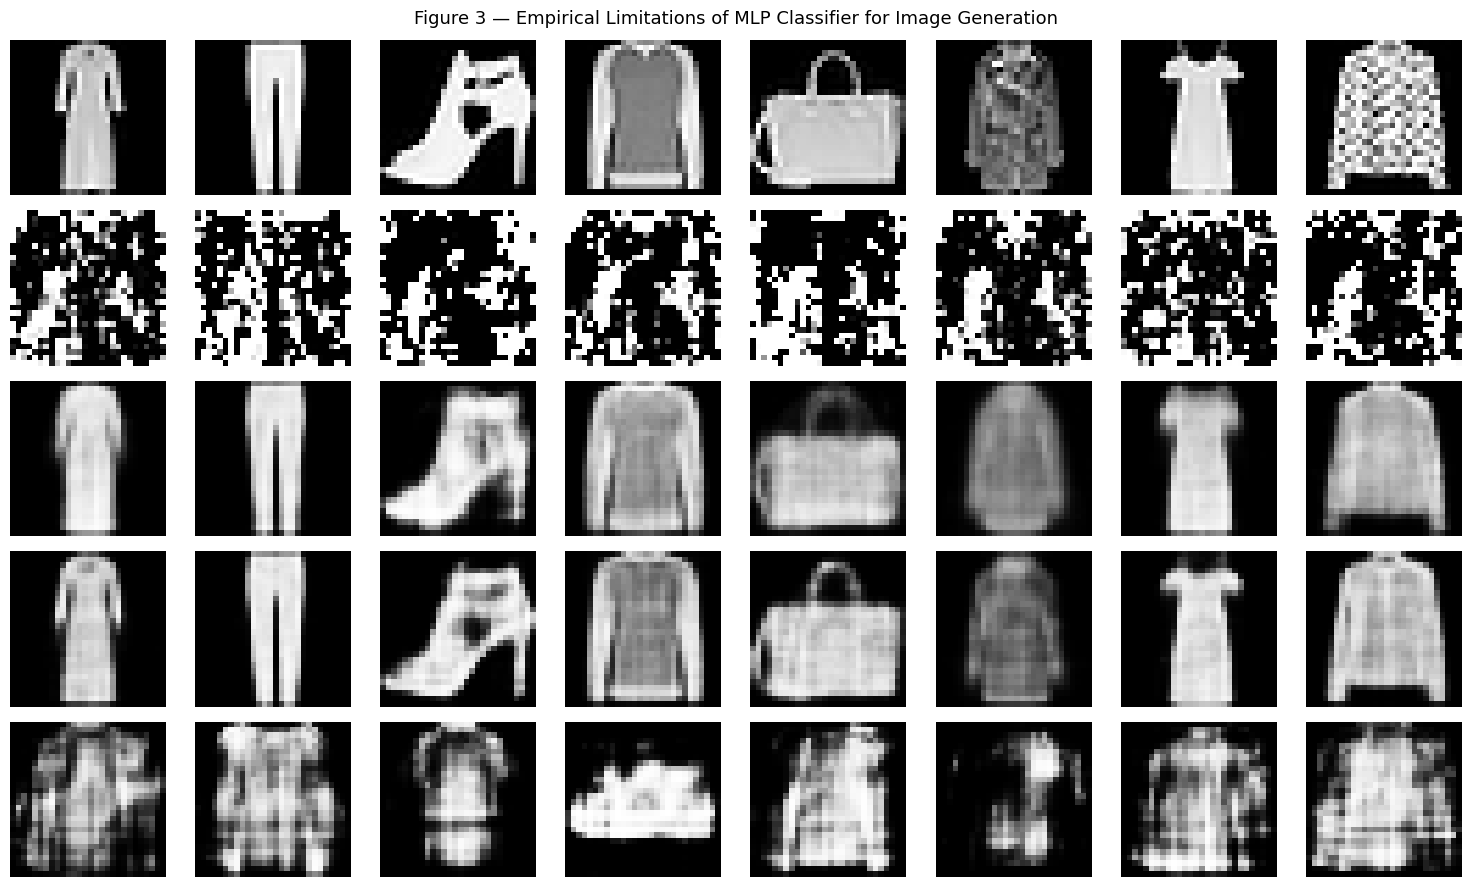

Figure 3 saved: /content/drive/MyDrive/Generative_Models_Take_Home/figures/figure3_mlp_generation_limitations.png
Rows: original, transpose projection, frozen decoder, AE reconstruction, prior samples


In [ ]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import numpy as np

N_FIG3 = 8

@torch.no_grad()
def build_figure3():
    mlp64.eval()
    frozen_decoder.eval()
    vanilla_ae.eval()

    # Same test images are used for every reconstruction row.
    x, labels = next(iter(test_loader))
    x = x[:N_FIG3].to(DEVICE)

    # 1. Original images
    originals = x

    # 2. Direct transpose-weight projection from z_MLP
    z_mlp = mlp64.extract_latent(x)
    h1_projection = F.relu(z_mlp @ mlp64.fc2.weight)
    x_projection = torch.sigmoid(
        h1_projection @ mlp64.fc1.weight
    ).view(-1, 1, 28, 28)

    # 3. Trainable frozen-latent decoder reconstruction
    x_frozen_decoder = frozen_decoder(z_mlp).clamp(0, 1)

    # 4. Vanilla AE reconstruction
    x_ae_reconstruction = vanilla_ae(x).clamp(0, 1)

    # 5. Random prior samples from empirical MLP latent statistics
    latent_mean, latent_std = estimate_latent_statistics(train_loader)
    z_random = latent_mean + latent_std * torch.randn(
        N_FIG3, MLP_LATENT_DIM, device=DEVICE
    )
    x_prior_samples = frozen_decoder(z_random).clamp(0, 1)

    rows = [
        ("Original", originals),
        ("MLP transpose projection", x_projection),
        ("Frozen MLP decoder", x_frozen_decoder),
        ("Vanilla AE reconstruction", x_ae_reconstruction),
        ("MLP empirical prior samples", x_prior_samples),
    ]

    fig, axes = plt.subplots(
        len(rows), N_FIG3, figsize=(15, 9)
    )

    for row_idx, (row_name, image_batch) in enumerate(rows):
        for col in range(N_FIG3):
            image = (
                image_batch[col, 0]
                .detach()
                .cpu()
                .numpy()
            )

            axes[row_idx, col].imshow(
                image, cmap="gray", vmin=0, vmax=1
            )
            axes[row_idx, col].axis("off")

        axes[row_idx, 0].set_ylabel(
            row_name, rotation=90, labelpad=30
        )

    fig.suptitle(
        "Figure 3 — Empirical Limitations of MLP Classifier for Image Generation",
        fontsize=13
    )
    plt.tight_layout()

    path = FIGURES_DIR / "figure3_mlp_generation_limitations.png"
    fig.savefig(path, dpi=250, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    print("Figure 3 saved:", path)
    print("Rows: original, transpose projection, frozen decoder, AE reconstruction, prior samples")


build_figure3()

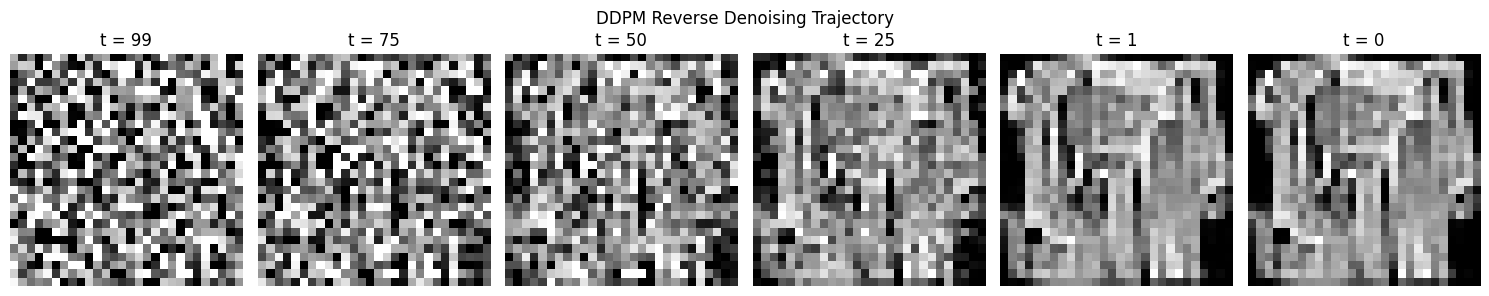

DDPM trajectory saved: /content/drive/MyDrive/Generative_Models_Take_Home/figures/ddpm_denoising_trajectory.png


In [ ]:
import torch
import matplotlib.pyplot as plt

@torch.no_grad()
def make_ddpm_trajectory():
    ddpm_model.eval()

    # One fixed initial noise sample.
    x = torch.randn(1, 1, 28, 28, device=DEVICE)

    # Save selected states throughout reverse diffusion.
    selected_steps = sorted(set([
        T - 1,
        int(T * 0.75),
        int(T * 0.50),
        int(T * 0.25),
        1,
        0
    ]), reverse=True)

    trajectory = {T - 1: x.clone()}

    for t_value in reversed(range(T)):
        t = torch.full(
            (1,), t_value, device=DEVICE, dtype=torch.long
        )

        predicted_noise = ddpm_model(x, t)

        alpha_t = alphas[t_value]
        alpha_bar_t = alpha_bars[t_value]
        beta_t = betas[t_value]

        x = (
            x - (beta_t / torch.sqrt(1 - alpha_bar_t))
            * predicted_noise
        ) / torch.sqrt(alpha_t)

        if t_value > 0:
            x = x + torch.sqrt(beta_t) * torch.randn_like(x)

        if t_value in selected_steps:
            trajectory[t_value] = x.clone()

    # Convert reverse-process states from [-1, 1] to [0, 1].
    display_steps = sorted(trajectory.keys(), reverse=True)

    fig, axes = plt.subplots(1, len(display_steps), figsize=(15, 3))

    for ax, step in zip(axes, display_steps):
        image = (
            ((trajectory[step] + 1) / 2)
            .clamp(0, 1)[0, 0]
            .detach()
            .cpu()
            .numpy()
        )

        ax.imshow(image, cmap="gray", vmin=0, vmax=1)
        ax.set_title(f"t = {step}")
        ax.axis("off")

    fig.suptitle("DDPM Reverse Denoising Trajectory")
    plt.tight_layout()

    path = FIGURES_DIR / "ddpm_denoising_trajectory.png"
    fig.savefig(path, dpi=250, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    print("DDPM trajectory saved:", path)


make_ddpm_trajectory()

In [ ]:
import math
import numpy as np
import pandas as pd
import torch
from torchmetrics.functional.image import (
    structural_similarity_index_measure
)

@torch.no_grad()
def evaluate_reconstruction_metrics(model, loader, model_name):
    model.eval()

    all_mse = []
    all_psnr = []
    weighted_ssim = 0.0
    total_images = 0

    for x, _ in loader:
        x = x.to(DEVICE, non_blocking=True)

        if model_name == "Frozen MLP latent decoder":
            z = mlp64.extract_latent(x)
            reconstruction = frozen_decoder(z)
        else:
            reconstruction = model(x)

        reconstruction = reconstruction.clamp(0, 1)

        # Per-image MSE and PSNR.
        mse_per_image = (
            (reconstruction - x)
            .pow(2)
            .flatten(start_dim=1)
            .mean(dim=1)
        )

        psnr_per_image = 10.0 * torch.log10(
            1.0 / mse_per_image.clamp_min(1e-12)
        )

        # SSIM for this batch; images are normalized to [0, 1].
        batch_ssim = structural_similarity_index_measure(
            reconstruction,
            x,
            data_range=1.0
        )

        batch_count = x.shape[0]
        all_mse.extend(mse_per_image.cpu().tolist())
        all_psnr.extend(psnr_per_image.cpu().tolist())

        weighted_ssim += float(batch_ssim.item()) * batch_count
        total_images += batch_count

    return {
        "model": model_name,
        "test_mse": float(np.mean(all_mse)),
        "test_psnr_db": float(np.mean(all_psnr)),
        "test_ssim": weighted_ssim / total_images,
        "n_test_images": total_images
    }


vanilla_ae_metrics = evaluate_reconstruction_metrics(
    vanilla_ae, test_loader, "Vanilla AE"
)

frozen_decoder_metrics = evaluate_reconstruction_metrics(
    frozen_decoder, test_loader, "Frozen MLP latent decoder"
)

comparison_df = pd.DataFrame([
    vanilla_ae_metrics,
    frozen_decoder_metrics
])

comparison_path = METRICS_DIR / "mlp_vs_ae_reconstruction_metrics.csv"
comparison_df.to_csv(comparison_path, index=False)

print(comparison_df.to_string(index=False))
print("\nSaved:", comparison_path)
print("STEP 13 COMPLETE")

                    model  test_mse  test_psnr_db  test_ssim  n_test_images
               Vanilla AE  0.007044     22.565352   0.852541           7000
Frozen MLP latent decoder  0.017732     18.320285   0.706420           7000

Saved: /content/drive/MyDrive/Generative_Models_Take_Home/metrics/mlp_vs_ae_reconstruction_metrics.csv
STEP 13 COMPLETE


In [ ]:
from pathlib import Path
import pandas as pd

for filename in [
    "reconstruction_metrics.csv",
    "inference_latency.csv",
    "fid_metrics.csv",
    "frozen_decoder_metrics.csv",
    "mlp_vs_ae_reconstruction_metrics.csv",
]:
    path = METRICS_DIR / filename
    print(f"\n{'=' * 15} {filename} {'=' * 15}")

    if path.exists():
        print(pd.read_csv(path).to_string(index=False))
    else:
        print("File belum ditemukan.")


=============== reconstruction_metrics.csv ===============
Unnamed: 0  test_mse  test_psnr_db  test_ssim  n_test_images
Vanilla AE  0.007044     22.565352   0.813935           7000
 Sparse AE  0.006994     22.609628   0.815736           7000
       VAE  0.013493     19.524657   0.701861           7000

=============== inference_latency.csv ===============
      model  batch_size  mean_latency_ms_batch64  std_latency_ms  latency_ms_per_image  benchmark_repeats device
 Vanilla AE          64                 0.601911        0.284991              0.009405                 15   cuda
  Sparse AE          64                 0.788608        0.414968              0.012322                 15   cuda
        VAE          64                 0.394073        0.020187              0.006157                 15   cuda
Vanilla GAN          64                 0.534170        0.064820              0.008346                 15   cuda
      DCGAN          64                 6.336181        0.452248            

In [ ]:
from torchmetrics.functional.image import (
    structural_similarity_index_measure
)
import torch
import pandas as pd

def get_reconstruction_tensor(output, batch_size):
    """Extract the image reconstruction from model output."""
    if torch.is_tensor(output):
        return output

    if isinstance(output, (tuple, list)):
        # Prefer a tensor matching the image batch shape.
        for item in output:
            if (
                torch.is_tensor(item)
                and item.ndim == 4
                and item.shape[0] == batch_size
                and item.shape[1:] == (1, 28, 28)
            ):
                return item

        # If no image tensor was found, show output structure.
        raise ValueError(
            "Tidak menemukan tensor rekonstruksi. "
            f"Output types: {[type(v).__name__ for v in output]}; "
            f"tensor shapes: "
            f"{[tuple(v.shape) for v in output if torch.is_tensor(v)]}"
        )

    raise TypeError(f"Unsupported model output: {type(output)}")


@torch.no_grad()
def audit_ssim_fixed(model, loader, model_name):
    model.eval()
    weighted_score = 0.0
    total_images = 0

    for x, _ in loader:
        x = x.to(DEVICE, non_blocking=True)

        if model_name == "VAE":
            output = model(x)
        else:
            output = model(x)

        reconstruction = get_reconstruction_tensor(
            output, x.shape[0]
        ).clamp(0, 1)

        score = structural_similarity_index_measure(
            reconstruction, x, data_range=1.0
        )

        weighted_score += float(score.item()) * x.shape[0]
        total_images += x.shape[0]

    return {
        "model": model_name,
        "test_ssim_torchmetrics": weighted_score / total_images,
        "n_test_images": total_images
    }


ssim_audit = pd.DataFrame([
    audit_ssim_fixed(vanilla_ae, test_loader, "Vanilla AE"),
    audit_ssim_fixed(sparse_ae, test_loader, "Sparse AE"),
    audit_ssim_fixed(vae, test_loader, "VAE")
])

print(ssim_audit.to_string(index=False))

     model  test_ssim_torchmetrics  n_test_images
Vanilla AE                0.852541           7000
 Sparse AE                0.036223           7000
       VAE                0.022442           7000


In [ ]:
import torch

x, _ = next(iter(test_loader))
x = x[:4].to(DEVICE)

models_to_check = [
    ("Vanilla AE", vanilla_ae),
    ("Sparse AE", sparse_ae),
    ("VAE", vae),
]

for name, model in models_to_check:
    model.eval()

    with torch.no_grad():
        output = model(x)

    print(f"\n--- {name} ---")
    print("Output type:", type(output).__name__)

    if isinstance(output, (tuple, list)):
        for i, item in enumerate(output):
            if torch.is_tensor(item):
                print(f"Output[{i}] shape:", tuple(item.shape))
                print(
                    f"Output[{i}] range:",
                    float(item.min()),
                    "to",
                    float(item.max())
                )
            else:
                print(f"Output[{i}] type:", type(item).__name__)
    elif torch.is_tensor(output):
        print("Shape:", tuple(output.shape))
        print("Range:", float(output.min()), "to", float(output.max()))


--- Vanilla AE ---
Output type: Tensor
Shape: (4, 1, 28, 28)
Range: 2.9040279295872162e-12 to 0.9842358827590942

--- Sparse AE ---
Output type: tuple
Output[0] shape: (4, 1, 28, 28)
Output[0] range: 0.45681673288345337 to 0.5493143200874329
Output[1] shape: (4, 64)
Output[1] range: -0.38996952772140503 to 0.31717821955680847

--- VAE ---
Output type: tuple
Output[0] shape: (4, 1, 28, 28)
Output[0] range: 0.26927831768989563 to 0.7051881551742554
Output[1] shape: (4, 64)
Output[1] range: -0.442998468875885 to 0.35928216576576233
Output[2] shape: (4, 64)
Output[2] range: -0.3225136697292328 to 0.3247920870780945


In [ ]:
import torch
import pandas as pd
from torchmetrics.functional.image import (
    structural_similarity_index_measure
)

@torch.no_grad()
def calculate_ssim_corrected(model, loader, name):
    model.eval()
    total_score = 0.0
    total_count = 0

    for x, _ in loader:
        x = x.to(DEVICE, non_blocking=True)
        output = model(x)

        if isinstance(output, (tuple, list)):
            reconstruction = output[0]
        else:
            reconstruction = output

        reconstruction = reconstruction.clamp(0, 1)

        score = structural_similarity_index_measure(
            reconstruction,
            x,
            data_range=1.0
        )

        total_score += score.item() * x.shape[0]
        total_count += x.shape[0]

    return {
        "model": name,
        "test_ssim": total_score / total_count,
        "n_test_images": total_count
    }


ssim_results = pd.DataFrame([
    calculate_ssim_corrected(vanilla_ae, test_loader, "Vanilla AE"),
    calculate_ssim_corrected(sparse_ae, test_loader, "Sparse AE"),
    calculate_ssim_corrected(vae, test_loader, "VAE")
])

print(ssim_results.to_string(index=False))

     model  test_ssim  n_test_images
Vanilla AE   0.852541           7000
 Sparse AE   0.036223           7000
       VAE   0.022607           7000


In [ ]:
import inspect

for name, model in [
    ("Vanilla AE", vanilla_ae),
    ("Sparse AE", sparse_ae),
    ("VAE", vae),
]:
    print(f"\n{'=' * 20} {name} {'=' * 20}")

    for method_name in ["forward", "encode", "decode"]:
        method = getattr(model, method_name, None)
        if method is not None:
            try:
                print(f"\n--- {method_name} ---")
                print(inspect.getsource(method))
            except (OSError, TypeError):
                print(f"Source untuk {method_name} tidak tersedia.")


==================== Vanilla AE ====================

--- forward ---
    def forward(self, x):
        z = self.encode(x)
        return self.decode(z)


--- encode ---
    def encode(self, x):
        return self.encoder(x)


--- decode ---
    def decode(self, z):
        x = self.decoder(z)
        return x.view(-1, 1, 28, 28)


==================== Sparse AE ====================

--- forward ---
    def forward(self, x):
        z = self.encode(x)
        reconstruction = self.decode(z)
        return reconstruction, z


--- encode ---
    def encode(self, x):
        return self.encoder(x)


--- decode ---
    def decode(self, z):
        x = self.decoder(z)
        return x.view(-1, 1, 28, 28)


==================== VAE ====================

--- forward ---
    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        reconstruction = self.decode(z)
        return reconstruction, mu, logvar


--- encode ---
    def encode(self

In [ ]:
import torch
import pandas as pd
from torchmetrics.functional.image import (
    structural_similarity_index_measure
)

@torch.no_grad()
def reconstruction_diagnostic(model, loader, name):
    model.eval()
    all_mse = []
    all_ssim = []
    recon_min = float("inf")
    recon_max = float("-inf")
    input_min = float("inf")
    input_max = float("-inf")
    n = 0

    for x, _ in loader:
        x = x.to(DEVICE, non_blocking=True)
        output = model(x)

        reconstruction = (
            output[0] if isinstance(output, (tuple, list))
            else output
        )
        reconstruction = reconstruction.clamp(0, 1)

        all_mse.append(
            ((reconstruction - x) ** 2).flatten(1).mean(1).cpu()
        )

        # SSIM calculated per image to avoid batch-level ambiguity.
        for i in range(x.shape[0]):
            score = structural_similarity_index_measure(
                reconstruction[i:i+1],
                x[i:i+1],
                data_range=1.0
            )
            all_ssim.append(score.item())

        recon_min = min(recon_min, reconstruction.min().item())
        recon_max = max(recon_max, reconstruction.max().item())
        input_min = min(input_min, x.min().item())
        input_max = max(input_max, x.max().item())
        n += x.shape[0]

    mse = torch.cat(all_mse).mean().item()

    return {
        "model": name,
        "test_mse": mse,
        "test_ssim_per_image": sum(all_ssim) / len(all_ssim),
        "input_min": input_min,
        "input_max": input_max,
        "reconstruction_min": recon_min,
        "reconstruction_max": recon_max,
        "n_test_images": n
    }


diagnostics = pd.DataFrame([
    reconstruction_diagnostic(vanilla_ae, test_loader, "Vanilla AE"),
    reconstruction_diagnostic(sparse_ae, test_loader, "Sparse AE"),
    reconstruction_diagnostic(vae, test_loader, "VAE")
])

print(diagnostics.to_string(index=False))

     model  test_mse  test_ssim_per_image  input_min  input_max  reconstruction_min  reconstruction_max  n_test_images
Vanilla AE  0.007044             0.852541        0.0        1.0        6.591228e-20            0.997044           7000
 Sparse AE  0.170473             0.036223        0.0        1.0        4.526764e-01            0.561890           7000
       VAE  0.173213             0.022616        0.0        1.0        2.010966e-01            0.787071           7000


In [ ]:
import inspect

# Tampilkan konfigurasi model dan fungsi training yang tersedia.
for name in [
    "sparse_ae", "vae",
    "train_sparse_ae", "train_vae",
    "sparse_ae_loss", "vae_loss",
    "sparse_loss", "vae_objective"
]:
    obj = globals().get(name)

    if obj is None:
        continue

    print(f"\n{'=' * 15} {name} {'=' * 15}")

    if isinstance(obj, torch.nn.Module):
        print(obj)
    elif callable(obj):
        try:
            print(inspect.getsource(obj))
        except (OSError, TypeError):
            print("Source tidak tersedia.")


=============== sparse_ae ===============
SparseAE(
  (encoder): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=256, bias=True)
    (2): ReLU()
    (3): Linear(in_features=256, out_features=64, bias=True)
  )
  (decoder): Sequential(
    (0): Linear(in_features=64, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=784, bias=True)
    (3): Sigmoid()
  )
)

=============== vae ===============
VAE(
  (encoder_body): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=256, bias=True)
    (2): ReLU()
  )
  (fc_mu): Linear(in_features=256, out_features=64, bias=True)
  (fc_logvar): Linear(in_features=256, out_features=64, bias=True)
  (decoder): Sequential(
    (0): Linear(in_features=64, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=784, bias=True)
    (3): Sigmoid()
  )
)

=============== sparse_ae_loss =

In [ ]:
# Periksa konfigurasi yang berpengaruh pada training.
for name in [
    "SPARSE_L1_LAMBDA",
    "LEARNING_RATE",
    "LR",
    "BATCH_SIZE",
    "NUM_EPOCHS",
    "EPOCHS",
]:
    if name in globals():
        print(f"{name} = {globals()[name]}")

# Periksa apakah training history masih tersimpan.
for name in [
    "sparse_history",
    "sparse_ae_history",
    "vae_history",
    "history_sparse_ae",
    "history_vae",
]:
    if name in globals():
        print(f"\n{name}:")
        print(str(globals()[name])[:2000])

SPARSE_L1_LAMBDA = 0.001
BATCH_SIZE = 128

history_vae:
[{'epoch': 1, 'train_loss': 299.9737416445937, 'val_loss': 273.89291770241476, 'epoch_time_seconds': 8.074558993999972}, {'epoch': 2, 'train_loss': 267.3657114386014, 'val_loss': 262.67969831986863, 'epoch_time_seconds': 8.157437681999909}, {'epoch': 3, 'train_loss': 258.28054715509285, 'val_loss': 255.79616088867186, 'epoch_time_seconds': 8.18401138199988}, {'epoch': 4, 'train_loss': 252.8475108734549, 'val_loss': 251.77583534934303, 'epoch_time_seconds': 8.088461854000116}, {'epoch': 5, 'train_loss': 249.93461023618096, 'val_loss': 249.55648470791903, 'epoch_time_seconds': 8.0656024110001}, {'epoch': 6, 'train_loss': 248.17463279967984, 'val_loss': 248.15505898215554, 'epoch_time_seconds': 8.111633536999989}, {'epoch': 7, 'train_loss': 246.9145482729559, 'val_loss': 246.98087463378906, 'epoch_time_seconds': 8.395573418999902}, {'epoch': 8, 'train_loss': 245.97111169823773, 'val_loss': 246.26297440962358, 'epoch_time_seconds': 7.

In [ ]:
import inspect

# 1. Cari seluruh variabel history yang tersedia.
for name, value in list(globals().items()):
    if "history" in name.lower() and isinstance(value, list):
        if value and isinstance(value[0], dict):
            print(f"\n--- {name} ---")
            print("Jumlah epoch:", len(value))
            print("Epoch pertama:", value[0])
            print("Epoch terakhir:", value[-1])

# 2. Tampilkan source fungsi training yang relevan.
for name, obj in list(globals().items()):
    if callable(obj) and any(
        term in name.lower()
        for term in ["train_sparse", "train_vae", "fit_sparse", "fit_vae"]
    ):
        print(f"\n--- FUNCTION: {name} ---")
        try:
            print(inspect.getsource(obj))
        except (OSError, TypeError):
            print("Source tidak tersedia melalui inspect.")


--- history_ae ---
Jumlah epoch: 20
Epoch pertama: {'epoch': 1, 'train_loss': 0.032617217605959065, 'val_loss': 0.0187595644119111, 'epoch_time_seconds': 8.103844392000042}
Epoch terakhir: {'epoch': 20, 'train_loss': 0.0069732885067797686, 'val_loss': 0.0071442412889816545, 'epoch_time_seconds': 7.785007303000043}

--- history_sparse ---
Jumlah epoch: 20
Epoch pertama: {'epoch': 1, 'train_loss': 0.0332507004017291, 'val_loss': 0.019195345890792935, 'epoch_time_seconds': 7.863640874999987}
Epoch terakhir: {'epoch': 20, 'train_loss': 0.007278409475018377, 'val_loss': 0.00748492998325012, 'epoch_time_seconds': 7.865732062999996}

--- history_vae ---
Jumlah epoch: 20
Epoch pertama: {'epoch': 1, 'train_loss': 299.9737416445937, 'val_loss': 273.89291770241476, 'epoch_time_seconds': 8.074558993999972}
Epoch terakhir: {'epoch': 20, 'train_loss': 241.82596135248332, 'val_loss': 242.4380235151811, 'epoch_time_seconds': 8.208163380000087}

--- history_gan ---
Jumlah epoch: 20
Epoch pertama: {'ep

In [ ]:
from pathlib import Path
import torch

CHECKPOINT_DIR = Path(
    "/content/drive/MyDrive/Generative_Models_Take_Home/checkpoints"
)

model_checkpoint_map = {
    "Vanilla AE": (vanilla_ae, "vanilla_ae.pt"),
    "Sparse AE": (sparse_ae, "sparse_ae.pt"),
    "VAE": (vae, "vae.pt"),
}

for name, (model, filename) in model_checkpoint_map.items():
    path = CHECKPOINT_DIR / filename
    print(f"\n--- {name} ---")
    print("Checkpoint:", path)
    print("Exists:", path.exists())

    if not path.exists():
        continue

    checkpoint = torch.load(
        path, map_location="cpu", weights_only=False
    )

    print("Checkpoint type:", type(checkpoint).__name__)

    if isinstance(checkpoint, dict):
        print("Keys:", list(checkpoint.keys()))

        # Detect common state-dict layouts without loading or changing weights.
        state_dict = None
        for key in ["model_state_dict", "state_dict", "model"]:
            if key in checkpoint and isinstance(checkpoint[key], dict):
                state_dict = checkpoint[key]
                break

        if state_dict is None and all(
            torch.is_tensor(v) for v in checkpoint.values()
        ):
            state_dict = checkpoint

        if state_dict is not None:
            current = model.state_dict()
            matching = (
                set(current.keys()) == set(state_dict.keys())
                and all(
                    current[k].shape == state_dict[k].shape
                    for k in current
                )
            )
            print("Parameter names/shapes match:", matching)
        else:
            print("State dict belum teridentifikasi otomatis.")


--- Vanilla AE ---
Checkpoint: /content/drive/MyDrive/Generative_Models_Take_Home/checkpoints/vanilla_ae.pt
Exists: True
Checkpoint type: dict
Keys: ['model_name', 'epoch', 'model_state_dict', 'optimizer_state_dict', 'history', 'seed', 'extra']
Parameter names/shapes match: True

--- Sparse AE ---
Checkpoint: /content/drive/MyDrive/Generative_Models_Take_Home/checkpoints/sparse_ae.pt
Exists: True
Checkpoint type: dict
Keys: ['model_name', 'epoch', 'model_state_dict', 'optimizer_state_dict', 'history', 'seed', 'extra']
Parameter names/shapes match: True

--- VAE ---
Checkpoint: /content/drive/MyDrive/Generative_Models_Take_Home/checkpoints/vae.pt
Exists: True
Checkpoint type: dict
Keys: ['model_name', 'epoch', 'model_state_dict', 'optimizer_state_dict', 'history', 'seed', 'extra']
Parameter names/shapes match: True


In [ ]:
import hashlib
import torch

def state_hash(state_dict):
    h = hashlib.sha256()
    for key in sorted(state_dict):
        tensor = state_dict[key].detach().cpu().contiguous()
        h.update(key.encode())
        h.update(tensor.numpy().tobytes())
    return h.hexdigest()

checkpoint_dir = (
    "/content/drive/MyDrive/Generative_Models_Take_Home/checkpoints"
)

models_to_verify = [
    ("Vanilla AE", vanilla_ae, "vanilla_ae.pt"),
    ("Sparse AE", sparse_ae, "sparse_ae.pt"),
    ("VAE", vae, "vae.pt"),
]

for name, model, filename in models_to_verify:
    path = f"{checkpoint_dir}/{filename}"

    # Keep a copy of current weights in memory.
    original_state = {
        k: v.detach().cpu().clone()
        for k, v in model.state_dict().items()
    }
    original_hash = state_hash(original_state)

    checkpoint = torch.load(
        path, map_location="cpu", weights_only=False
    )
    checkpoint_state = checkpoint["model_state_dict"]
    checkpoint_hash = state_hash(checkpoint_state)

    print(f"\n--- {name} ---")
    print("In-memory hash :", original_hash)
    print("Checkpoint hash:", checkpoint_hash)
    print("Weights identical:", original_hash == checkpoint_hash)

    # Restore the model's original in-memory weights.
    model.load_state_dict(original_state)


--- Vanilla AE ---
In-memory hash : b0e03d69b4f601890ead1c40ddce114333845f9fde606e325710942e13fae0ae
Checkpoint hash: b0e03d69b4f601890ead1c40ddce114333845f9fde606e325710942e13fae0ae
Weights identical: True

--- Sparse AE ---
In-memory hash : 79383d0d025d7720f2c6201d30d49aed010366ba74810eea1690baeafbbbf350
Checkpoint hash: d4e18c174546d2c8fb3027922ebe53aba006edecf79552c89bfa30705514b388
Weights identical: False

--- VAE ---
In-memory hash : f89fc885309668c5a38c066430abd24f659413bdd2d73829310166d0d9ebfd58
Checkpoint hash: ef84bf16fb726cb06f6af05386990b82e4e9cf9a1f0a3b6f32894d2b9a4037c4
Weights identical: False


In [ ]:
import torch
from pathlib import Path

checkpoint_dir = Path(
    "/content/drive/MyDrive/Generative_Models_Take_Home/checkpoints"
)

for filename in ["vanilla_ae.pt", "sparse_ae.pt", "vae.pt"]:
    path = checkpoint_dir / filename
    ckpt = torch.load(
        path, map_location="cpu", weights_only=False
    )

    print(f"\n{'=' * 15} {filename} {'=' * 15}")
    print("Model name:", ckpt.get("model_name"))
    print("Saved epoch:", ckpt.get("epoch"))
    print("Seed:", ckpt.get("seed"))
    print("Extra metadata:", ckpt.get("extra"))

    history = ckpt.get("history")
    if isinstance(history, list) and history:
        print("History length:", len(history))
        print("First epoch:", history[0])
        print("Last epoch:", history[-1])


=============== vanilla_ae.pt ===============
Model name: vanilla_ae
Saved epoch: 20
Seed: 42
Extra metadata: {'model_type': 'vanilla_ae', 'latent_dim': 64, 'learning_rate': 0.001, 'sparse_l1_lambda': None}
History length: 20
First epoch: {'epoch': 1, 'train_loss': 0.032617217605959065, 'val_loss': 0.0187595644119111, 'epoch_time_seconds': 8.103844392000042}
Last epoch: {'epoch': 20, 'train_loss': 0.0069732885067797686, 'val_loss': 0.0071442412889816545, 'epoch_time_seconds': 7.785007303000043}

=============== sparse_ae.pt ===============
Model name: sparse_ae
Saved epoch: 20
Seed: 42
Extra metadata: {'model_type': 'sparse_ae', 'latent_dim': 64, 'learning_rate': 0.001, 'sparse_l1_lambda': 0.001}
History length: 20
First epoch: {'epoch': 1, 'train_loss': 0.0332507004017291, 'val_loss': 0.019195345890792935, 'epoch_time_seconds': 7.863640874999987}
Last epoch: {'epoch': 20, 'train_loss': 0.007278409475018377, 'val_loss': 0.00748492998325012, 'epoch_time_seconds': 7.865732062999996}

==

In [ ]:
from pathlib import Path
import torch
import pandas as pd
from torchmetrics.functional.image import (
    structural_similarity_index_measure
)

checkpoint_dir = Path(
    "/content/drive/MyDrive/Generative_Models_Take_Home/checkpoints"
)

@torch.no_grad()
def evaluate_loaded_checkpoint(model, filename, name):
    checkpoint = torch.load(
        checkpoint_dir / filename,
        map_location=DEVICE,
        weights_only=False
    )

    model.load_state_dict(checkpoint["model_state_dict"])
    model.eval()

    squared_error_sum = 0.0
    ssim_sum = 0.0
    image_count = 0

    for x, _ in test_loader:
        x = x.to(DEVICE, non_blocking=True)
        output = model(x)

        reconstruction = (
            output[0] if isinstance(output, (tuple, list))
            else output
        ).clamp(0, 1)

        squared_error_sum += (
            (reconstruction - x).square().sum().item()
        )

        # Calculate SSIM per image for a consistent average.
        for i in range(x.shape[0]):
            score = structural_similarity_index_measure(
                reconstruction[i:i+1],
                x[i:i+1],
                data_range=1.0
            )
            ssim_sum += score.item()

        image_count += x.shape[0]

    mse = squared_error_sum / (image_count * 28 * 28)
    mean_ssim = ssim_sum / image_count

    return {
        "model": name,
        "checkpoint_epoch": checkpoint["epoch"],
        "test_mse": mse,
        "test_ssim": mean_ssim,
        "n_test_images": image_count
    }


checkpoint_results = pd.DataFrame([
    evaluate_loaded_checkpoint(
        sparse_ae, "sparse_ae.pt", "Sparse AE"
    ),
    evaluate_loaded_checkpoint(
        vae, "vae.pt", "VAE"
    )
])

print(checkpoint_results.to_string(index=False))

    model  checkpoint_epoch  test_mse  test_ssim  n_test_images
Sparse AE                20  0.006994   0.851860           7000
      VAE                20  0.015795   0.734062           7000


In [ ]:
from pathlib import Path
import torch
import pandas as pd
from torchmetrics.functional.image import (
    structural_similarity_index_measure
)

checkpoint_dir = Path(
    "/content/drive/MyDrive/Generative_Models_Take_Home/checkpoints"
)
metrics_dir = Path(
    "/content/drive/MyDrive/Generative_Models_Take_Home/metrics"
)
metrics_dir.mkdir(parents=True, exist_ok=True)

models = [
    (vanilla_ae, "vanilla_ae.pt", "Vanilla AE"),
    (sparse_ae, "sparse_ae.pt", "Sparse AE"),
    (vae, "vae.pt", "VAE"),
]

@torch.no_grad()
def evaluate_checkpoint(model, filename, name):
    ckpt = torch.load(
        checkpoint_dir / filename,
        map_location=DEVICE,
        weights_only=False
    )
    model.load_state_dict(ckpt["model_state_dict"])
    model.eval()

    mse_sum = 0.0
    ssim_sum = 0.0
    n = 0

    for x, _ in test_loader:
        x = x.to(DEVICE, non_blocking=True)
        output = model(x)
        recon = output[0] if isinstance(output, (tuple, list)) else output
        recon = recon.clamp(0, 1)

        mse_sum += (recon - x).square().sum().item()

        # SSIM averaged per image.
        for i in range(x.shape[0]):
            ssim_sum += structural_similarity_index_measure(
                recon[i:i+1], x[i:i+1], data_range=1.0
            ).item()

        n += x.shape[0]

    return {
        "model": name,
        "test_mse": mse_sum / (n * 28 * 28),
        "test_ssim": ssim_sum / n,
        "n_test_images": n,
        "checkpoint_epoch": ckpt["epoch"]
    }


final_reconstruction_metrics = pd.DataFrame([
    evaluate_checkpoint(model, filename, name)
    for model, filename, name in models
])

output_path = metrics_dir / "reconstruction_metrics_final.csv"
final_reconstruction_metrics.to_csv(output_path, index=False)

print(final_reconstruction_metrics.to_string(index=False))
print("\nSaved:", output_path)

     model  test_mse  test_ssim  n_test_images  checkpoint_epoch
Vanilla AE  0.007044   0.852541           7000                20
 Sparse AE  0.006994   0.851860           7000                20
       VAE  0.015807   0.734566           7000                20

Saved: /content/drive/MyDrive/Generative_Models_Take_Home/metrics/reconstruction_metrics_final.csv


In [ ]:
from pathlib import Path
import pandas as pd

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Generative_Models_Take_Home"
)
METRICS_DIR = PROJECT_DIR / "metrics"

files = {
    "reconstruction": "reconstruction_metrics_final.csv",
    "latency": "inference_latency.csv",
    "fid": "fid_metrics.csv",
}

for label, filename in files.items():
    path = METRICS_DIR / filename
    print(f"{label}: {'FOUND' if path.exists() else 'MISSING'} — {path}")

recon = pd.read_csv(METRICS_DIR / files["reconstruction"])
latency = pd.read_csv(METRICS_DIR / files["latency"])
fid = pd.read_csv(METRICS_DIR / files["fid"])

print("\n--- Reconstruction columns ---")
print(recon.columns.tolist())

print("\n--- Latency columns ---")
print(latency.columns.tolist())

print("\n--- FID columns ---")
print(fid.columns.tolist())

print("\n--- Training histories available ---")
for name in [
    "history_ae", "history_sparse", "history_vae",
    "history_gan", "history_dcgan", "history_ddpm"
]:
    if name in globals():
        history = globals()[name]
        print(name, "epochs =", len(history))
        if history:
            print("  first:", history[0])
            print("  last :", history[-1])

reconstruction: FOUND — /content/drive/MyDrive/Generative_Models_Take_Home/metrics/reconstruction_metrics_final.csv
latency: FOUND — /content/drive/MyDrive/Generative_Models_Take_Home/metrics/inference_latency.csv
fid: FOUND — /content/drive/MyDrive/Generative_Models_Take_Home/metrics/fid_metrics.csv

--- Reconstruction columns ---
['model', 'test_mse', 'test_ssim', 'n_test_images', 'checkpoint_epoch']

--- Latency columns ---
['model', 'batch_size', 'mean_latency_ms_batch64', 'std_latency_ms', 'latency_ms_per_image', 'benchmark_repeats', 'device']

--- FID columns ---
['model', 'fid_score', 'real_samples', 'generated_samples', 'feature_extractor']

--- Training histories available ---
history_ae epochs = 20
  first: {'epoch': 1, 'train_loss': 0.032617217605959065, 'val_loss': 0.0187595644119111, 'epoch_time_seconds': 8.103844392000042}
  last : {'epoch': 20, 'train_loss': 0.0069732885067797686, 'val_loss': 0.0071442412889816545, 'epoch_time_seconds': 7.785007303000043}
history_sparse 

In [ ]:
from pathlib import Path
import pandas as pd

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Generative_Models_Take_Home"
)
METRICS_DIR = PROJECT_DIR / "metrics"

# Load existing metrics
recon = pd.read_csv(
    METRICS_DIR / "reconstruction_metrics_final.csv"
)
latency = pd.read_csv(
    METRICS_DIR / "inference_latency.csv"
)
fid = pd.read_csv(
    METRICS_DIR / "fid_metrics.csv"
)

# Normalize model names for merging
def normalize_name(name):
    name = str(name).strip().lower()
    return {
        "vanilla ae": "vanilla_ae",
        "sparse ae": "sparse_ae",
        "vae": "vae",
        "vanilla gan": "vanilla_gan",
        "dcgan": "dcgan",
        "ddpm": "ddpm",
    }.get(name, name.replace(" ", "_"))

for df in [recon, latency, fid]:
    df["model_key"] = df["model"].apply(normalize_name)

# Calculate training time from recorded epoch histories
history_map = {
    "vanilla_ae": history_ae,
    "sparse_ae": history_sparse,
    "vae": history_vae,
    "vanilla_gan": history_gan,
    "dcgan": history_dcgan,
    "ddpm": history_ddpm,
}

training_rows = []
for model_key, history in history_map.items():
    times = [
        row["epoch_time_seconds"]
        for row in history
        if "epoch_time_seconds" in row
    ]

    training_rows.append({
        "model_key": model_key,
        "epochs": len(times),
        "mean_epoch_seconds": (
            sum(times) / len(times) if times else None
        ),
        "total_epoch_seconds": (
            sum(times) if times else None
        ),
    })

training = pd.DataFrame(training_rows)

# Merge all available results
table = recon.merge(
    latency[
        ["model_key", "mean_latency_ms_batch64",
         "latency_ms_per_image", "device"]
    ],
    on="model_key", how="outer"
)

table = table.merge(
    fid[["model_key", "fid_score"]],
    on="model_key", how="outer"
)

table = table.merge(training, on="model_key", how="outer")

# Keep a consistent display order
order = [
    "vanilla_ae", "sparse_ae", "vae",
    "vanilla_gan", "dcgan", "ddpm"
]
table["sort_order"] = table["model_key"].map(
    {name: i for i, name in enumerate(order)}
)
table = table.sort_values("sort_order").drop(
    columns=["sort_order", "model_key"]
)

# Round numeric columns for readability
for col in table.select_dtypes(include="number").columns:
    table[col] = table[col].round(5)

output_path = METRICS_DIR / "final_comparison_table.csv"
table.to_csv(output_path, index=False)

print(table.to_string(index=False))
print("\nSaved:", output_path)

     model  test_mse  test_ssim  n_test_images  checkpoint_epoch  mean_latency_ms_batch64  latency_ms_per_image device  fid_score  epochs  mean_epoch_seconds  total_epoch_seconds
Vanilla AE   0.00704    0.85254         7000.0              20.0                  0.60191               0.00940   cuda        NaN      20             7.78760            155.75196
 Sparse AE   0.00699    0.85186         7000.0              20.0                  0.78861               0.01232   cuda        NaN      20             7.85057            157.01130
       VAE   0.01581    0.73457         7000.0              20.0                  0.39407               0.00616   cuda   97.13606      20             8.08714            161.74282
       NaN       NaN        NaN            NaN               NaN                  0.53417               0.00835   cuda  167.51083      20             8.65384            173.07671
       NaN       NaN        NaN            NaN               NaN                  6.33618               0

In [ ]:
from pathlib import Path
import pandas as pd

METRICS_DIR = Path(
    "/content/drive/MyDrive/Generative_Models_Take_Home/metrics"
)

recon = pd.read_csv(
    METRICS_DIR / "reconstruction_metrics_final.csv"
)
latency = pd.read_csv(
    METRICS_DIR / "inference_latency.csv"
)
fid = pd.read_csv(
    METRICS_DIR / "fid_metrics.csv"
)

# Canonical model names
def canonical(name):
    s = str(name).strip().lower().replace("_", " ")
    mapping = {
        "vanilla ae": "Vanilla AE",
        "sparse ae": "Sparse AE",
        "vae": "VAE",
        "vanilla gan": "Vanilla GAN",
        "dcgan": "DCGAN",
        "ddpm": "DDPM",
    }
    return mapping.get(s, str(name).strip())

for df in (recon, latency, fid):
    df["model"] = df["model"].apply(canonical)

# Use one row per model, with a common model name
table = pd.DataFrame({
    "model": [
        "Vanilla AE", "Sparse AE", "VAE",
        "Vanilla GAN", "DCGAN", "DDPM"
    ]
})

table = table.merge(
    recon[["model", "test_mse", "test_ssim", "n_test_images"]],
    on="model", how="left"
)

table = table.merge(
    latency[[
        "model", "mean_latency_ms_batch64",
        "latency_ms_per_image", "device"
    ]],
    on="model", how="left"
)

table = table.merge(
    fid[["model", "fid_score"]],
    on="model", how="left"
)

# Training histories must already exist in notebook memory
history_map = {
    "Vanilla AE": history_ae,
    "Sparse AE": history_sparse,
    "VAE": history_vae,
    "Vanilla GAN": history_gan,
    "DCGAN": history_dcgan,
    "DDPM": history_ddpm,
}

training_rows = []
for model, history in history_map.items():
    times = [
        r["epoch_time_seconds"]
        for r in history
        if "epoch_time_seconds" in r
    ]
    training_rows.append({
        "model": model,
        "epochs": len(times),
        "mean_epoch_seconds": (
            sum(times) / len(times) if times else None
        ),
        "total_epoch_seconds": (
            sum(times) if times else None
        ),
    })

table = table.merge(
    pd.DataFrame(training_rows), on="model", how="left"
)

out = METRICS_DIR / "final_comparison_table.csv"
table.to_csv(out, index=False)

print(table.round(5).to_string(index=False))
print("\nSaved:", out)

      model  test_mse  test_ssim  n_test_images  mean_latency_ms_batch64  latency_ms_per_image device  fid_score  epochs  mean_epoch_seconds  total_epoch_seconds
 Vanilla AE   0.00704    0.85254         7000.0                  0.60191               0.00940   cuda        NaN      20             7.78760            155.75196
  Sparse AE   0.00699    0.85186         7000.0                  0.78861               0.01232   cuda        NaN      20             7.85057            157.01130
        VAE   0.01581    0.73457         7000.0                  0.39407               0.00616   cuda   97.13606      20             8.08714            161.74282
Vanilla GAN       NaN        NaN            NaN                  0.53417               0.00835   cuda  167.51083      20             8.65384            173.07671
      DCGAN       NaN        NaN            NaN                  6.33618               0.09900   cuda   36.83029      20            12.74537            254.90732
       DDPM       NaN       

In [ ]:
from pathlib import Path

root = Path(
    "/content/drive/MyDrive/Generative_Models_Take_Home"
)

files_to_check = [
    "metrics/final_comparison_table.csv",
    "metrics/reconstruction_metrics_final.csv",
    "metrics/inference_latency.csv",
    "metrics/fid_metrics.csv",
    "figures/figure1_reconstruction.png",
    "figures/figure2_random_sampling.png",
    "figures/figure3_mlp_generation_limitations.png",
    "figures/figure4_latent_interpolation.png",
    "figures/figure5_training_loss_curves.png",
    "figures/ddpm_denoising_trajectory.png",
    "figures/mlp_classifier_training.png",
]

for relative_path in files_to_check:
    path = root / relative_path
    status = "OK" if path.exists() else "MISSING"
    print(f"[{status}] {relative_path}")

[OK] metrics/final_comparison_table.csv
[OK] metrics/reconstruction_metrics_final.csv
[OK] metrics/inference_latency.csv
[OK] metrics/fid_metrics.csv
[OK] figures/figure1_reconstruction.png
[OK] figures/figure2_random_sampling.png
[OK] figures/figure3_mlp_generation_limitations.png
[OK] figures/figure4_latent_interpolation.png
[OK] figures/figure5_training_loss_curves.png
[OK] figures/ddpm_denoising_trajectory.png
[OK] figures/mlp_classifier_training.png
